# D30. LiveKit 심화 & Speech-to-Speech: Multi-agent Handoff · SIP 전화 · OpenAI Realtime · Gemini Live

**음성 AI 전문가 과정 (160h) | 6주차 M6 실시간 음성 파이프라인 (Pipecat · LiveKit) | 4시간**

## 학습 목표
1. 비서에게 **도구(`@function_tool`)** 를 주고, 통화 중에 **예약 담당 → 수납 담당**으로 넘기는 **Multi-agent Handoff**를 만든다. 담당이 바뀌어도 이어지는 정보는 **`userdata`** 에 담는다.
2. 로컬 Qwen3 플러그인에 **도구 호출(`FunctionToolCall`)** 을 더해, 클라우드 LLM과 같은 방식으로 도구를 부르게 한다.
3. **SIP 전화 연동**의 구조(PSTN → SIP Trunk → Dispatch Rule → Room → Agent)를 설명하고, 인바운드 · 아웃바운드 요청을 코드로 만든다. **전화 음질(8 kHz · μ-law)** 이 받아쓰기에 미치는 영향을 귀와 숫자로 확인한다.
4. **Speech-to-Speech(S2S)** 모델(OpenAI Realtime · Gemini Live)을 같은 대본(Agent)에 꽂아 보고, **Cascade(STT → LLM → TTS)** 와 지연 · 제어 · 비용을 비교한다.
5. 전화 음질의 가짜 통화로 **예약 → 수납 Handoff 전체 통화**를 작업자(fake job)에서 돌리고, 통화 기록을 남긴다.

## 오늘의 실습 흐름
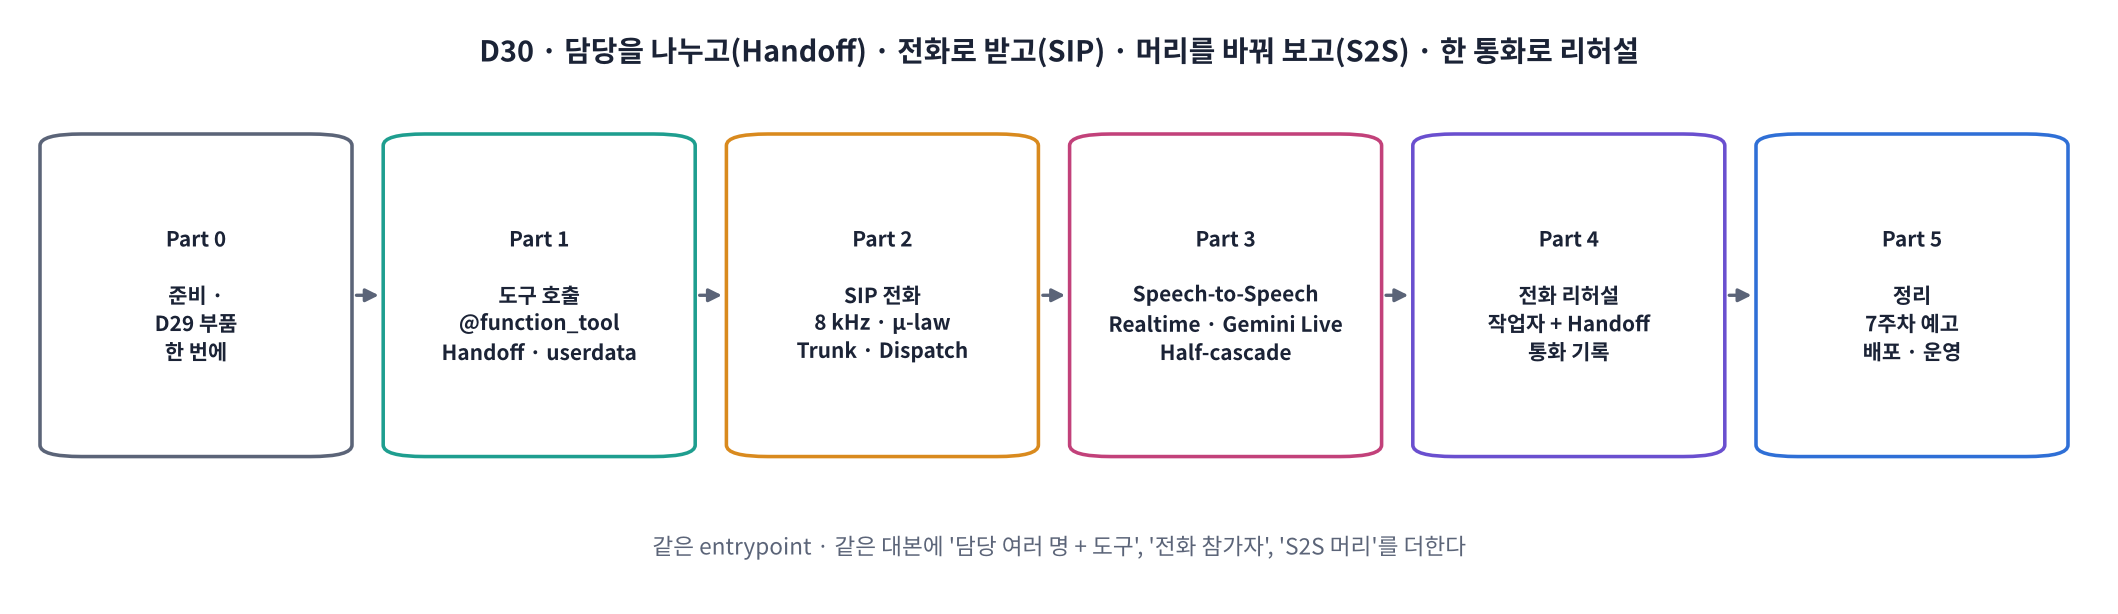

| 교시 | 내용 | 실습 | 산출물 |
|---|---|---|---|
| 1교시 | D29 복습, 도구 호출 플러그인, `@function_tool`, `userdata`, Handoff | Part 0 ~ 1, 워크시트 1교시 | 3턴 대화의 사건(event) 표 · 담당 변화 |
| 2교시 | SIP 전화: 구조 · 전화 음질 · Trunk / Dispatch Rule / Outbound Call 요청 | Part 2, 워크시트 2교시 | 전화 음질 비교(소리 · 스펙트로그램 · 받아쓰기 오류) · SIP 요청서 |
| 3교시 | Speech-to-Speech: OpenAI Realtime · Gemini Live · Half-cascade | Part 3, 워크시트 3교시 | 모델별 능력(capabilities) 표 · (키가 있으면) S2S 통화 지연 |
| 4교시 | 통합: 전화 음질 + Handoff 통화를 작업자로, 통화 기록, 정리 | Part 4 ~ 5, 워크시트 4교시 | 통화 타임라인(담당별 색) · `call_log.json` · Cascade vs S2S 표 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day30/animation.html) | 도구 호출(D30-2) · Handoff(D30-3) · SIP(D30-4 · 5) · 전화 음질(D30-6) · S2S(D30-7 · 8) |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day30/worksheet.html) | 각 교시 끝에 해당 탭 10문항 (4교시 × 10문항), 오답 캡처 → 노션 |

## 이 노트북 사용법
- ▶️ 위에서부터 차례로 실행합니다. Part 0의 **'D29 부품'** 셀이 어제 만든 플러그인 · 가짜 마이크 · 스피커를 한 번에 준비합니다.
- 🧩 **빈칸 실습** 셀은 `____`를 채우고 실행하면 ✅ 또는 ❌가 나옵니다. 🔑 **정답 및 해설 보기**를 누르면 정답이 펼쳐집니다.
- ✏️ 표시 셀은 값을 **직접 바꿔** 다시 실행해 보는 셀입니다.
- ⏳ Part 4의 통화는 **실제 시간으로 흐르므로** 40 ~ 70초가 걸립니다.

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 기억할 식 하나 |
| ❓ **생각해 보기** | 스스로 답해 보고 펼쳐서 확인 |
| 🎧 **들어 보기** | 소리로 확인 |

> ⚙️ **런타임 → T4 GPU**. 🔑 **LLM 키 (선택, 권장)**: 오늘은 **도구 호출**이 핵심이라 `ANTHROPIC_API_KEY` · `OPENAI_API_KEY` · `GEMINI_API_KEY` 중 하나가 있으면 훨씬 안정적입니다. 없으면 **로컬 Qwen3-4B**(T4)로 도구를 부릅니다.
>
> 🎙️ **S2S 키 (선택, Part 3)**: `OPENAI_API_KEY`가 있으면 **OpenAI Realtime**, `GEMINI_API_KEY`가 있으면 **Gemini Live**로 실제 음성 통화를 해 봅니다. 없으면 구조 · 능력 비교까지 진행합니다.
>
> ☎️ **SIP (선택, 강사 시연)**: 실제 전화를 걸려면 LiveKit Cloud 키 3개 + SIP Trunk(Twilio · Telnyx 등) + 전화번호가 필요합니다. 키 · 전화번호 · 녹음은 화면 · 노션 · 깃허브에 올리지 않습니다.

> 🎬 **애니메이션 D30-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day30/animation.html#flow) — Part 1~5 로드맵과 시간 계획

## Part 0. 준비 (D29와 같은 모델 + Google 플러그인)

> 🛠️ `[silero,openai,google]`: 오늘은 **OpenAI Realtime**(openai 플러그인 안에 있음)과 **Gemini Live**(google 플러그인)를 씁니다.

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요, 1 ~ 2분)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "torchcodec", "transformers", "tokenizers", "huggingface-hub", "datasets",
        "accelerate", "diffusers", "numpy", "scipy", "librosa", "numba", "safetensors", "requests",
        "click", "filelock", "rich", "typer", "pydantic", "httpx"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))
!pip install -q -c colab_constraints.txt "livekit-agents[silero,openai,google]==1.8.10" "livekit-api>=1.2"
!pip install -q -c colab_constraints.txt uroman edge-tts scipy
print("✅ 설치 완료")

In [ ]:
import os, re, sys, json, time, random, socket, asyncio, warnings, logging
from dataclasses import dataclass
import numpy as np
import pandas as pd
import librosa
import torch
import matplotlib.pyplot as plt
from IPython.display import Audio, display, Markdown
import importlib.metadata as md
warnings.filterwarnings("ignore")
logging.getLogger("transformers").setLevel(logging.ERROR)
for _name in ["livekit", "livekit.agents", "livekit.plugins"]:   # LiveKit은 logging으로 로그를 남김 → 오류만 보이게
    logging.getLogger(_name).setLevel(logging.ERROR)
from threading import Thread
from transformers import TextIteratorStreamer

from livekit import rtc, api                             # rtc: 방 · 참가자 · 트랙(WebRTC) · api: 토큰 · 서버 API
from livekit.agents import (Agent, AgentSession, AgentServer, JobContext, JobExecutorType, RunContext,
                            function_tool, utils, APIConnectOptions)
from livekit.agents import stt as lk_stt, tts as lk_tts, llm as lk_llm   # 플러그인 부모 클래스 (stt · tts는 아래 Whisper · TTS 함수 이름과 겹쳐서 lk_를 붙임)
from livekit.agents.voice import io as lk_io             # 소리 입출력 자리 (AudioInput · AudioOutput)
from livekit.plugins import silero, openai as lk_openai, google as lk_google   # 플러그인: Silero VAD · OpenAI(호환 LLM · Realtime) · Google(Gemini Live)
from dataclasses import field

GPU = torch.cuda.is_available()
DEVICE = "cuda" if GPU else "cpu"
SR = 16000
print(" · ".join(f"{p} {md.version(p)}" for p in ["livekit-agents", "livekit-plugins-google", "livekit-api", "torch", "transformers"]))
print("GPU:", torch.cuda.get_device_name(0) if GPU else "없음 (CPU로도 가능)")

def check(cond, hint="빈칸을 다시 확인하세요."):
    print("✅ 정답입니다! 🎉" if cond else f"❌ {hint}")

def set_seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if GPU: torch.cuda.manual_seed_all(s)

def to_np(y):
    y = y.detach().cpu().numpy() if torch.is_tensor(y) else np.asarray(y)
    return y.reshape(-1).astype(np.float32)

def play(y, sr=SR, label=""):
    y = to_np(y)
    print(f"🎧 {label}  ({len(y) / sr:.2f}초)")
    if len(y): display(Audio(y, rate=sr))
    else: print("   (소리 없음: 위의 경고 · 오류를 확인하세요)")

def silence(sec, sr=SR):
    return np.zeros(int(sec * sr), np.float32)

# D16 정규화 (숫자 → 읽는 말): TTS 바로 앞에서 씀
DIGITS = "영일이삼사오육칠팔구"
def sino(n):
    if n == 0: return "영"
    out = ""
    for big in ["", "만", "억", "조"]:
        chunk, n = n % 10000, n // 10000; s = ""
        for i, unit in enumerate(["", "십", "백", "천"]):
            d, chunk = chunk % 10, chunk // 10
            if d: s = ("" if d == 1 and i > 0 else DIGITS[d]) + unit + s
        if s: out = ("" if s == "일" and big == "만" else s) + big + out
        if n == 0: break
    return out
ONES = ["", "한", "두", "세", "네", "다섯", "여섯", "일곱", "여덟", "아홉"]
TENS = ["", "열", "스물", "서른", "마흔", "쉰", "예순", "일흔", "여든", "아흔"]
def native(n): return sino(n) if not 0 < n < 100 else ("스무" if n == 20 else TENS[n // 10] + ONES[n % 10])
NATIVE_COUNTERS = ["시간", "개", "명", "살", "마리", "권", "잔", "병", "장", "달", "시"]
def normalize_ko(t):
    t = re.sub(r"(\d+)\s*(" + "|".join(NATIVE_COUNTERS) + ")", lambda m: native(int(m.group(1))) + " " + m.group(2), t)
    t = re.sub(r"(\d+)\s*%", lambda m: sino(int(m.group(1))) + " 퍼센트", t)
    t = re.sub(r"\d+", lambda m: sino(int(m.group(0))), t)
    return re.sub(r"\s+", " ", t).strip()
print(normalize_ko("오후 2시에 3명, 주차는 2시간 무료, 할인 10%"))

In [ ]:
# 🔊 모델 준비 (D27 ~ D29와 같음): 받아쓰기 Whisper · 합성 Edge TTS (예비 MMS-TTS) + 오늘의 사용자 말 세 마디
from transformers import AutoTokenizer, VitsModel, WhisperProcessor, WhisperForConditionalGeneration
import uroman as ur
tts_tok = AutoTokenizer.from_pretrained("facebook/mms-tts-kor")
tts_model = VitsModel.from_pretrained("facebook/mms-tts-kor").to(DEVICE).eval()
U = ur.Uroman()
ASR_NAME = "openai/whisper-small" if GPU else "openai/whisper-tiny"
asr_proc = WhisperProcessor.from_pretrained(ASR_NAME)
asr = WhisperForConditionalGeneration.from_pretrained(ASR_NAME).to(DEVICE).eval()

import functools, tempfile
VOICE_BOT, VOICE_USER = "ko-KR-SunHiNeural", "ko-KR-InJoonNeural"   # ✏️ Edge 신경망 음성: 비서 · 사용자 대역
TTS_ENGINE = "edge"                                      # 인터넷 · 서비스 문제로 실패하면 자동으로 "mms"(예비)

@functools.lru_cache(maxsize=512)                        # 같은 문장은 다시 요청하지 않음
def _edge_tts(text, voice):
    import edge_tts
    fd, path = tempfile.mkstemp(suffix=".mp3"); os.close(fd)
    try:
        edge_tts.Communicate(text, voice).save_sync(path)
        return librosa.load(path, sr=SR)[0].astype(np.float32)   # MP3 24 kHz → 16 kHz
    finally:
        os.remove(path)

def _mms_tts(text, seed=0):                              # 예비: MMS-TTS 한국어 VITS (D16)
    set_seed(seed)
    enc = tts_tok(U.romanize_string(text), return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        return to_np(tts_model(**enc).waveform[0])

def tts(text, seed=0, voice=None):                       # 글자 → 16 kHz 소리: Edge 신경망 음성, 실패하면 MMS-TTS
    global TTS_ENGINE
    if TTS_ENGINE == "edge":
        try:
            return _edge_tts(text, voice or VOICE_BOT).copy()
        except Exception as e:
            print(f"⚠️ Edge TTS 실패 → MMS-TTS로 전환 ({type(e).__name__}: {str(e)[:80]})"); TTS_ENGINE = "mms"
    return _mms_tts(text, seed)

def user_tts(text, seed=0):                              # 사용자 대역 목소리: 비서와 다른 목소리 (MMS 예비일 때는 3반음 낮춰 구분)
    y = tts(text, seed=seed, voice=VOICE_USER)
    return librosa.effects.pitch_shift(y, sr=SR, n_steps=-3) if TTS_ENGINE == "mms" else y

def stt(y):                                              # 16 kHz 소리 → 글자
    feats = asr_proc.feature_extractor(to_np(y), sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
    with torch.no_grad():
        ids = asr.generate(input_features=feats, language="korean", task="transcribe", max_new_tokens=96)
    return asr_proc.batch_decode(ids, skip_special_tokens=True)[0].strip()

def make_voice(text):                                    # 앞 0.5초 · 뒤 1초 조용함을 붙인 '사용자 말'
    y = np.concatenate([silence(0.5), user_tts(text), silence(1.0)]).astype(np.float32)
    return y / (np.abs(y).max() + 1e-9) * 0.8

SAY1 = "안녕하세요, 다음 주 수요일 오후 두 시에 스케일링 예약하고 싶어요. 이름은 김민준이에요."   # 오늘의 사용자 말 세 마디
SAY2 = "스케일링 비용은 얼마예요?"
SAY3 = "네, 알겠습니다. 감사합니다."
VOICE1, VOICE2, VOICE3 = make_voice(SAY1), make_voice(SAY2), make_voice(SAY3)
GREET = "안녕하세요, 한빛치과 예약 도우미 하나입니다. 무엇을 도와드릴까요?"
for i, v in enumerate([VOICE1, VOICE2, VOICE3], 1): play(v, SR, f"사용자 말 {i}")
print("받아쓰기 확인:", stt(VOICE1), "/", stt(VOICE2))

In [ ]:
# 🔑 LLM 고르기 (D22와 같음): 키가 있으면 클라우드, 없으면 로컬 Qwen3
def secret(name):
    try:
        from google.colab import userdata
        v = userdata.get(name)
        if v: return v
    except Exception:
        pass
    return os.environ.get(name) or None

MODELS = {"claude": "claude-haiku-5-5",                 # ✏️ 모델 이름은 수업 당일 각 회사 문서에서 확인
          "openai": "gpt-6-luna",
          "gemini": "gemini-3.5-flash-lite",
          "local": "Qwen/Qwen3-4B" if GPU else "Qwen/Qwen3-0.6B"}   # D30: 도구 호출이 있어 로컬은 4B (T4 fp16 약 8 GB)
KEYS = {"claude": "ANTHROPIC_API_KEY", "openai": "OPENAI_API_KEY", "gemini": "GEMINI_API_KEY"}
BASE_URLS = {"claude": "https://api.anthropic.com/v1/",                      # 세 회사 모두 'OpenAI 호환' 주소를 제공
             "openai": None,
             "gemini": "https://generativelanguage.googleapis.com/v1beta/openai/"}
AVAILABLE = [p for p in ["claude", "openai", "gemini"] if secret(KEYS[p])] + ["local"]
PROVIDER = AVAILABLE[0]                                  # ✏️ 바꿔 보기: "local" 등

if PROVIDER == "local":
    from transformers import AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained(MODELS["local"])
    llm_model = AutoModelForCausalLM.from_pretrained(MODELS["local"], dtype=torch.float16 if GPU else torch.float32).to(DEVICE).eval()

SYSTEM = ("당신은 한빛치과의 전화 예약 도우미입니다. 음성으로 답하므로 한두 문장의 짧은 구어체로 말하고, "
          "목록 · 기호 · 이모지는 쓰지 않습니다. 예약에는 날짜 · 시간 · 진료 · 이름이 필요하며, 빠진 것이 있으면 하나씩 물어봅니다.")
print("쓸 수 있는 LLM:", AVAILABLE, "→ 오늘 쓸 LLM:", PROVIDER, MODELS[PROVIDER])

In [ ]:
# 🧰 D29 부품 한 번에: STT · TTS 플러그인, 가짜 마이크 · 스피커, 통화 기록 · 그림 (빈칸 없음, 어제 만든 그대로)
class WhisperSTT(lk_stt.STT):                            # 귀: D29 Part 3-1
    def __init__(self):
        super().__init__(capabilities=lk_stt.STTCapabilities(streaming=False, interim_results=False))
    @property
    def model(self): return ASR_NAME
    async def _recognize_impl(self, buffer, *, language=None, conn_options=None):
        frame = rtc.combine_audio_frames(buffer)
        y = np.frombuffer(frame.data, dtype=np.int16).astype(np.float32) / 32768
        if frame.num_channels > 1: y = y.reshape(-1, frame.num_channels).mean(axis=1)
        if frame.sample_rate != SR: y = librosa.resample(y, orig_sr=frame.sample_rate, target_sr=SR)
        text = await asyncio.to_thread(stt, y)
        return lk_stt.SpeechEvent(type=lk_stt.SpeechEventType.FINAL_TRANSCRIPT, alternatives=[lk_stt.SpeechData(language="ko", text=text)])

class KoTTS(lk_tts.TTS):                                 # 입: D29 Part 3-2 (voice로 담당별 목소리를 바꿀 수 있게)
    def __init__(self, voice=None):
        super().__init__(capabilities=lk_tts.TTSCapabilities(streaming=False), sample_rate=SR, num_channels=1)
        self.voice = voice or VOICE_BOT
    @property
    def model(self): return "edge-tts " + self.voice if TTS_ENGINE == "edge" else "mms-tts-kor"
    def synthesize(self, text, *, conn_options=APIConnectOptions()):
        return KoChunk(tts=self, input_text=text, conn_options=conn_options)

class KoChunk(lk_tts.ChunkedStream):
    async def _run(self, output_emitter):
        y = await asyncio.to_thread(tts, normalize_ko(self.input_text), 0, self._tts.voice)
        output_emitter.initialize(request_id=utils.shortuuid(), sample_rate=SR, num_channels=1, mime_type="audio/pcm")
        output_emitter.push((np.clip(y, -1, 1) * 32767).astype(np.int16).tobytes())
        output_emitter.flush()

class FileMic(lk_io.AudioInput):                         # 가짜 마이크: 비서가 한 번 말하고 다시 듣는 중이 되면 다음 말
    def __init__(self, session, voices, gap=0.8, wait_bot=True):
        super().__init__(label="file-mic")
        self.s, self.queue, self.gap = session, list(voices), gap
        self.n = SR // 50; self.k = 0; self.t0 = None
        self.cur, self.pos, self.spans = None, 0, []
        self.need_bot = wait_bot; self.quiet_since = None
    def finished(self):
        return not self.queue and self.cur is None and not self.need_bot and self.s.agent_state == "listening"
    async def __anext__(self):
        if self.t0 is None: self.t0 = time.perf_counter()
        self.k += 1
        await asyncio.sleep(max(0.0, self.t0 + self.k * self.n / SR - time.perf_counter()))
        now = time.perf_counter() - self.t0
        state = self.s.agent_state
        if state == "speaking": self.need_bot = False
        if self.cur is None and self.queue and not self.need_bot:
            if state == "listening":
                self.quiet_since = self.quiet_since if self.quiet_since is not None else now
                if now - self.quiet_since >= self.gap:
                    self.cur, self.pos = self.queue.pop(0), 0; self.spans.append([now, None])
            else:
                self.quiet_since = None
        if self.cur is not None:
            chunk = self.cur[self.pos:self.pos + self.n]; self.pos += self.n
            if self.pos >= len(self.cur):
                self.spans[-1][1] = now + len(chunk) / SR; self.cur = None; self.need_bot = True; self.quiet_since = None
        else:
            chunk = np.zeros(0, np.float32)
        chunk = np.pad(chunk, (0, self.n - len(chunk)))
        return rtc.AudioFrame((np.clip(chunk, -1, 1) * 32767).astype(np.int16).tobytes(), SR, 1, self.n)

class Speaker(lk_io.AudioOutput):                        # 가짜 스피커: 실제 재생 시간만큼 기다렸다가 '재생 끝'
    def __init__(self, t0, session=None):
        super().__init__(label="speaker", capabilities=lk_io.AudioOutputCapabilities(pause=False), sample_rate=SR)
        self.t0, self.s = t0, session; self.chunks = []; self.seg_start = None; self.seg_len = 0.0; self.task = None
    async def capture_frame(self, frame):
        await super().capture_frame(frame)
        if self.seg_start is None:
            self.seg_start = time.perf_counter(); self.on_playback_started(created_at=time.time())
        y = np.frombuffer(frame.data, dtype=np.int16).astype(np.float32) / 32768
        if frame.sample_rate != SR: y = librosa.resample(y, orig_sr=frame.sample_rate, target_sr=SR)
        who = type(self.s.current_agent).__name__ if self.s is not None else ""
        self.chunks.append((self.seg_start - self.t0 + self.seg_len, y, who))     # (재생 시각, 소리, 말한 담당)
        self.seg_len += len(y) / SR
    def flush(self):
        super().flush()
        if self.seg_start is None: return
        start, length = self.seg_start, self.seg_len
        async def finish():
            await asyncio.sleep(max(0.0, start + length - time.perf_counter()))
            self.seg_start, self.seg_len = None, 0.0
            self.on_playback_finished(playback_position=length, interrupted=False)
        self.task = asyncio.ensure_future(finish())
    def clear_buffer(self):
        if self.seg_start is None: return
        if self.task: self.task.cancel()
        pos = min(self.seg_len, time.perf_counter() - self.seg_start)
        self.chunks = [c for c in self.chunks if c[0] < self.seg_start - self.t0 + pos]
        self.seg_start, self.seg_len = None, 0.0
        self.on_playback_finished(playback_position=pos, interrupted=True)

class CallLog:                                           # 세션 사건을 시각 · 담당과 함께 기록
    def __init__(self, session, t0):
        self.t0, self.states, self.items, self.who = t0, [], [], []
        session.on("agent_state_changed", lambda ev: self.states.append((time.perf_counter() - self.t0, ev.new_state)))
        def _item(ev):
            if ev.item.type == "message":
                self.items.append(ev.item); self.who.append(type(session.current_agent).__name__)
        session.on("conversation_item_added", _item)

def attach_fake_io(session, voices, t0):
    mic, spk = FileMic(session, voices), Speaker(t0, session)
    mic.t0 = t0
    session.input.audio, session.output.audio = mic, spk
    return mic, spk

async def wait_call(mic, max_wait=150, tail=1.0):
    t_end = time.perf_counter() + max_wait
    while time.perf_counter() < t_end and not mic.finished():
        await asyncio.sleep(0.1)
    await asyncio.sleep(tail)

def bot_spans(chunks, gap=0.3):                          # [(시작, 끝, 담당)]
    spans = []
    for t, y, who in chunks:
        a, b = t, t + len(y) / SR
        if spans and a - spans[-1][1] < gap and spans[-1][2] == who: spans[-1][1] = b
        else: spans.append([a, b, who])
    return spans

AGENT_COLORS = {"Hana": "#1E9E8F", "Billing": "#6A4FCF"}
def plot_call(res, title=""):
    spans_b = bot_spans(res["spk"].chunks); spans_u = [s for s in res["mic"].spans if s[1]]
    fig, ax = plt.subplots(figsize=(12, 2.6))
    for a, b, who in spans_b: ax.barh(1, b - a, left=a, color=AGENT_COLORS.get(who, "#1E9E8F"), height=0.5)
    for a, b in spans_u: ax.barh(0, b - a, left=a, color="#D98A1E", height=0.5)
    for who, c in AGENT_COLORS.items():
        if any(s[2] == who for s in spans_b): ax.barh(-10, 0, color=c, label=f"bot: {who}")
    ax.set_yticks([0, 1]); ax.set_yticklabels(["user (mic)", "bot (speaker)"]); ax.set_xlabel("seconds")   # 그림 글자는 영어
    ax.set_ylim(-0.5, 1.8); ax.set_title(title, fontsize=10)
    if spans_b: ax.legend(loc="upper right", fontsize=8)
    plt.tight_layout(); plt.show()
    return spans_b, spans_u

def turn_table(res):                                     # 메시지 + 담당 + metrics
    rows = []
    for it, who in zip(res["log"].items, res["log"].who):
        m = it.metrics or {}
        rows.append({"누가": "사용자" if it.role == "user" else f"비서({who})", "말": it.text_content[:34],
                     "턴 끝 판단": m.get("end_of_turn_delay"), "LLM TTFT": m.get("llm_node_ttft"),
                     "TTS TTFB": m.get("tts_node_ttfb"), "e2e": m.get("e2e_latency")})
    return pd.DataFrame(rows, columns=["누가", "말", "턴 끝 판단", "LLM TTFT", "TTS TTFB", "e2e"]).round(2)

def mix(res, voices):                                    # 사용자 + 비서 소리를 한 줄로
    end = max([t + len(y) / SR for t, y, _ in res["spk"].chunks] + [s[1] for s in res["mic"].spans if s[1]] + [1])
    out = np.zeros(int(end * SR) + SR, np.float32)
    for t, y, _ in res["spk"].chunks:
        i = int(t * SR); out[i:i + len(y)] += y[:len(out) - i]
    for (a, b), v in zip(res["mic"].spans, voices):
        if b: i = int(a * SR); out[i:i + len(v)] += v[:len(out) - i] * 0.9
    return out / (np.abs(out).max() + 1e-9) * 0.9

VAD = silero.VAD.load()
print("D29 부품 준비 완료: WhisperSTT · KoTTS · FileMic · Speaker · CallLog · plot_call · turn_table · mix")

### 🧭 D29 복습 → 오늘 더하는 것

| D29에서 만든 것 | 오늘 더하는 것 |
|---|---|
| `Agent(instructions=...)` 대본 하나 | 대본 **여러 개**와 **도구**(`@function_tool`), 담당 넘기기(**Handoff**) |
| 브라우저 · Python 참가자가 방에 들어옴 | **전화**가 방에 들어옴 (SIP 참가자) |
| STT → LLM → TTS (Cascade) 세 칸 | 세 칸을 **한 모델(Speech-to-Speech)** 로 |
| `session.run`으로 글자 시험 | 도구 호출 · Handoff까지 `result.expect`로 시험 |

**❓ 생각해 보기**: 어제의 한빛치과 비서에게 '스케일링 얼마예요?'라고 물으면 어떻게 될까요? 지시문(instructions)에 가격표를 다 넣으면 해결될까요?

<details>
<summary>답 보기</summary>

지시문에 없는 가격은 LLM이 **지어낼(hallucination)** 위험이 큽니다. 가격표를 지시문에 다 넣으면 프롬프트가 길어져 매 턴 비용 · 지연이 늘고, 예약 규칙과 수납 규칙이 섞여 서로 방해합니다. 그래서 ① 정확한 값은 **도구**(가격 조회 함수)가 돌려주게 하고 ② 예약과 수납을 **다른 담당(Agent)** 으로 나눠 각자 짧은 지시문 · 자기 도구만 갖게 합니다. 오늘 Part 1의 주제입니다.

</details>

## Part 1. 도구와 Multi-agent Handoff  ·  1교시

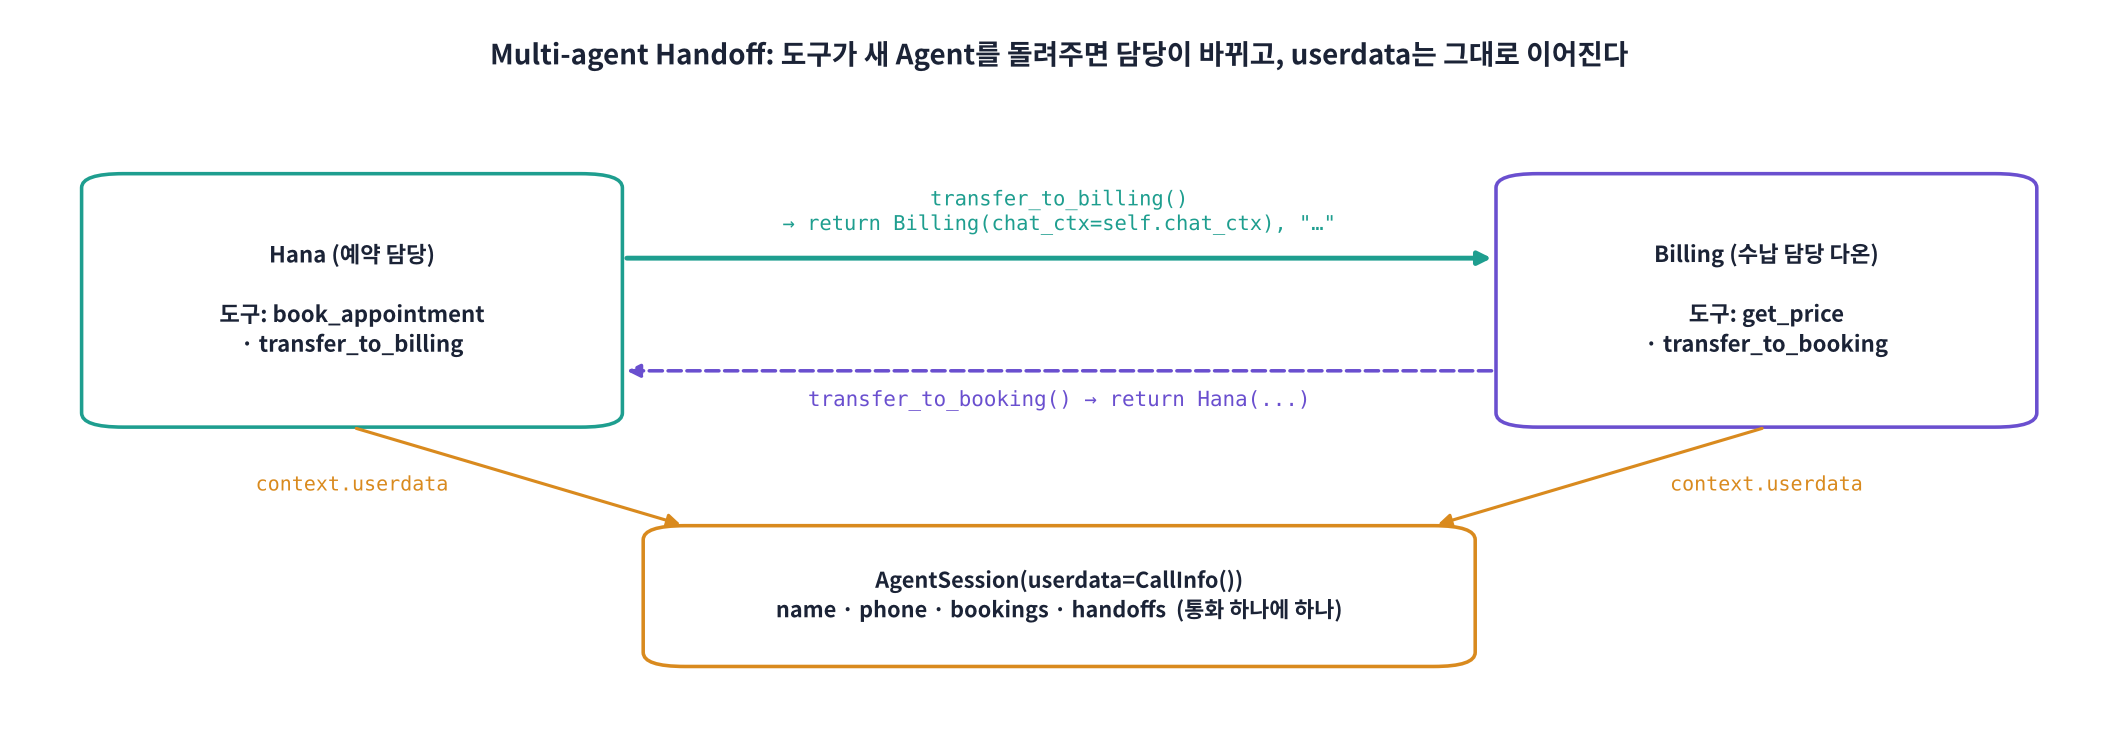

### 1-1. 도구 호출(Tool Calling)의 흐름 복습 (D23)

👣 **한 단계씩**
1. 세션이 LLM에 **대화 + 도구 설명서(이름 · 설명 · 인자)** 를 보냅니다.
2. LLM은 말 대신 **"이 도구를 이 인자로 불러 주세요"** (`FunctionToolCall`)를 돌려줄 수 있습니다.
3. 세션이 **우리 파이썬 함수를 실행**하고 결과를 대화에 붙입니다 (`function_call_output`).
4. 세션이 LLM을 **다시** 불러, 결과를 보고 사용자에게 할 말을 만들게 합니다.

> 💬 **쉽게 말하면**: LLM은 **주문서**만 쓰고, 실제 일(예약 저장 · 가격 조회)은 **우리 함수**가 합니다.

> 🎬 **애니메이션 D30-2:** [도구 호출 한 바퀴](https://imguru-mooc.github.io/AI_Voice/day30/animation.html#tools) — LLM → FunctionToolCall → 우리 함수 → 결과 → LLM이 다시 말하기

### 1-2. 로컬 Qwen3 플러그인에 도구 호출 더하기

클라우드 LLM(기성 `lk_openai.LLM`)은 도구 호출을 이미 지원합니다. D29의 `QwenLLM`은 글자만 보냈으므로, 오늘은 **Qwen3의 도구 호출 형식**을 LiveKit 형식으로 바꿔 주는 부분을 더합니다.

| | Qwen3가 쓰는 글자 | LiveKit이 받는 조각 |
|---|---|---|
| 말 | `네, 예약해 드릴게요.` | `ChoiceDelta(content="네, 예약해 드릴게요.")` |
| 도구 주문 | `<tool_call>{"name": "book_appointment", "arguments": {...}}</tool_call>` | `ChoiceDelta(tool_calls=[FunctionToolCall(name=..., arguments="{...}", call_id=...)])` |

> ⚖️ 도구가 있을 때는 Qwen3가 주문서를 쓰는지 말을 하는지 **끝까지 봐야** 알 수 있어, 글자를 **모았다가 한 번에** 보냅니다(첫 글자 TTFT가 늘어나는 대가). 클라우드 LLM은 서버가 이 구분을 해서 흘려 줍니다.

In [ ]:
# 🧩 빈칸 실습 1: 로컬 Qwen3 LLM 플러그인 + 도구 호출 (클라우드는 기성 플러그인 그대로)
TOOL_RE = re.compile(r"<tool_call>\s*(\{.*?\})\s*</tool_call>", re.S)

def split_tool_calls(text):                              # Qwen3 출력 → (사용자에게 할 말, [도구 주문 dict])
    calls = []
    for m in TOOL_RE.findall(text):
        try: calls.append(json.loads(m))
        except json.JSONDecodeError: pass                # 형식이 깨진 주문은 버림 (작은 모델에서 가끔)
    talk = re.sub(r"<tool_call>.*?(</tool_call>|$)", "", text, flags=re.S).strip()
    return talk, calls

class QwenLLM(lk_llm.LLM):
    @property
    def model(self): return MODELS["local"]
    def chat(self, *, chat_ctx, tools=None, conn_options=APIConnectOptions(), **kwargs):
        return QwenStream(self, chat_ctx=chat_ctx, tools=tools or [], conn_options=conn_options)

class QwenStream(lk_llm.LLMStream):
    async def _run(self):
        messages, _ = self._chat_ctx.to_provider_format("openai")          # 도구 주문 · 결과 메시지까지 OpenAI 모양으로
        schemas = lk_llm.ToolContext(self._tools).parse_function_tools("openai", strict=False) if self._tools else None
        it = qwen_stream(messages, schemas)
        rid, text = utils.shortuuid(), ""
        while (piece := await asyncio.to_thread(next, it, None)) is not None:
            if schemas is None:                                             # 도구가 없으면 D29처럼 바로바로 흘려보냄
                self._event_ch.send_nowait(lk_llm.ChatChunk(id=rid, delta=lk_llm.ChoiceDelta(role="assistant", content=piece)))
            else:
                text += piece                                               # 도구가 있으면 끝까지 모았다가 판단
        if schemas is None: return
        talk, calls = split_tool_calls(text)
        if talk:
            self._event_ch.send_nowait(lk_llm.ChatChunk(id=rid, delta=lk_llm.ChoiceDelta(role="assistant", content=talk)))
        for i, c in enumerate(calls):
            call = lk_llm.____(name=c["name"], arguments=json.dumps(c.get("arguments", {}), ensure_ascii=False),   # 빈칸 1: 도구 주문 한 장
                               call_id=f"{rid}_{i}")
            self._event_ch.send_nowait(lk_llm.ChatChunk(id=rid, delta=lk_llm.ChoiceDelta(role="assistant", tool_calls=[call])))

def qwen_stream(messages, tools=None):                   # Qwen3 채팅 템플릿에 도구 설명서를 넣어 생성 (글자를 흘려 주는 반복자)
    text = tok.apply_chat_template(messages, tools=tools, tokenize=False, add_generation_prompt=True, enable_thinking=False)
    enc = tok(text, return_tensors="pt").to(DEVICE)
    streamer = TextIteratorStreamer(tok, skip_prompt=True, skip_special_tokens=True)
    Thread(target=llm_model.generate, kwargs=dict(**enc, max_new_tokens=160, do_sample=False, repetition_penalty=1.05, streamer=streamer)).start()
    return iter(streamer)

def make_llm():
    if PROVIDER == "local":
        return QwenLLM()
    kw = {"base_url": BASE_URLS[PROVIDER]} if BASE_URLS[PROVIDER] else {}
    return lk_openai.LLM(model=MODELS[PROVIDER], api_key=secret(KEYS[PROVIDER]), **kw)

sample = '네, 예약해 드릴게요.\n<tool_call>\n{"name": "book_appointment", "arguments": {"date": "다음 주 수요일", "time": "14:00"}}\n</tool_call>'
talk, calls = split_tool_calls(sample)
print("말:", repr(talk), "· 도구 주문:", calls)
probe = lk_llm.____(name="book_appointment", arguments="{}", call_id="t0")
print("LiveKit 도구 주문 조각:", type(probe).__name__, probe.name)
check(isinstance(probe, lk_llm.FunctionToolCall) and calls[0]["name"] == "book_appointment", "LiveKit의 '도구 주문 한 장' 클래스 이름을 확인하세요.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
call = lk_llm.FunctionToolCall(name=c["name"], arguments=json.dumps(...), call_id=f"{rid}_{i}")
```

**해설**: `FunctionToolCall`은 '이 이름의 도구를 이 인자(JSON 글자)로 불러 달라'는 **주문서 한 장**입니다. `ChoiceDelta(tool_calls=[...])`에 담아 보내면 세션이 같은 이름의 `@function_tool` 함수를 찾아 실행하고, 결과를 `call_id`로 짝지어 대화에 붙입니다. `arguments`는 dict가 아니라 **JSON 글자**라는 점에 주의하세요.

</details>

### 1-3. 도구 달기: `@function_tool`과 `RunContext.userdata`

- Agent 클래스 안의 메서드에 **`@function_tool`** 을 붙이면 도구가 됩니다. **함수 이름 = 도구 이름**, **docstring = 도구 설명**, **매개변수(타입 힌트) = 인자**입니다. LLM은 이 설명서만 보고 언제 부를지 정하므로 docstring을 구체적으로 씁니다.
- 첫 인자 `context: RunContext[CallInfo]`로 **통화 하나에 하나**인 공유 메모 `context.userdata`에 접근합니다. 담당이 바뀌어도 `userdata`는 그대로입니다.
- 도구가 **새 Agent를 돌려주면** 세션이 그 Agent로 **담당을 바꿉니다(Handoff)**. `(새 Agent, "할 말")` 짝으로 돌려주면 그 말이 도구 결과가 됩니다.

> 🍎 **비유**: 병원 접수처(예약 담당)에서 "비용은 수납 창구에서 안내해 드릴게요" 하고 **환자 차트(userdata)를 들려 보내는** 것과 같습니다. 수납 창구는 차트를 보고 이어서 응대합니다.

> 🎬 **애니메이션 D30-3:** [Handoff와 공유 메모](https://imguru-mooc.github.io/AI_Voice/day30/animation.html#handoff) — 도구가 새 Agent를 돌려주는 순간, 대화 · userdata · 목소리가 어떻게 넘어가나

In [ ]:
# 🧩 빈칸 실습 2 · 3: 두 담당(예약 · 수납)과 도구, 공유 메모(userdata)
from types import SimpleNamespace
@dataclass
class CallInfo:                                          # 통화 하나에 하나: 담당이 바뀌어도 그대로 이어지는 메모
    name: str | None = None
    phone: str | None = None
    bookings: list = field(default_factory=list)
    handoffs: list = field(default_factory=list)

PRICES = {"스케일링": "보험 적용 시 약 1만 5천 원", "충치 치료": "레진 기준 약 10만 원부터",
          "미백": "약 30만 원 (2회)", "검진": "보험 적용 시 무료 ~ 약 5천 원"}           # 가상의 한빛치과 가격표

BOOKING_RULES = SYSTEM + " 날짜 · 시간 · 진료 · 이름이 모두 모이면 book_appointment 도구로 예약을 확정합니다. 비용 · 결제 질문은 transfer_to_billing 도구로 수납 담당에게 넘깁니다."
BILLING_RULES = ("당신은 한빛치과의 수납 안내 담당 '다온'입니다. 음성으로 한두 문장의 짧은 구어체로 답합니다. "
                 "비용은 반드시 get_price 도구로 확인한 값만 말하고, 예약 변경은 transfer_to_booking 도구로 예약 담당에게 넘깁니다.")

class Hana(Agent):                                       # 예약 담당
    def __init__(self, chat_ctx=None):
        super().__init__(instructions=BOOKING_RULES, chat_ctx=chat_ctx, tts=KoTTS(VOICE_BOT))

    @____
    async def book_appointment(self, context: RunContext[CallInfo], date: str, time: str, service: str, name: str) -> str:   # 빈칸 2: 메서드를 '도구'로 만드는 장식자
        '''예약을 확정합니다. 날짜 · 시간 · 진료 · 이름이 모두 확인된 뒤에만 부릅니다.

        Args:
            date: 예약 날짜 (예: 다음 주 수요일, 11월 11일)
            time: 예약 시간 (24시간제 HH:MM)
            service: 진료 종류 (스케일링 · 충치 치료 · 미백 · 검진)
            name: 환자 이름
        '''
        info = context.____                                  # 빈칸 3: 통화 하나에 하나인 공유 메모
        info.name = name
        no = f"HB-{len(info.bookings) + 1:04d}"
        info.bookings.append({"예약번호": no, "날짜": date, "시간": time, "진료": service, "이름": name})
        return f"예약 완료. 예약 번호 {no}, {date} {time} {service}, {name} 님."

    @function_tool
    async def transfer_to_billing(self, context: RunContext[CallInfo]):
        '''비용 · 결제 · 보험 질문이 나오면 수납 담당에게 넘깁니다.'''
        context.userdata.handoffs.append("Hana → Billing")
        return Billing(chat_ctx=self.chat_ctx), "비용은 수납 담당이 안내해 드릴게요."   # 새 Agent를 돌려주면 Handoff

VOICE_BILLING = "ko-KR-HyunsuMultilingualNeural"         # ✏️ 수납 담당 목소리 (Edge 신경망 음성)
class Billing(Agent):                                    # 수납 담당 (다른 목소리)
    def __init__(self, chat_ctx=None):
        super().__init__(instructions=BILLING_RULES, chat_ctx=chat_ctx, tts=KoTTS(VOICE_BILLING))

    async def on_enter(self):                            # 담당이 된 순간: 이어받은 대화를 보고 바로 응대
        self.session.generate_reply()

    @function_tool
    async def get_price(self, context: RunContext[CallInfo], service: str) -> str:
        '''진료 비용을 가격표에서 찾아 알려 줍니다.

        Args:
            service: 진료 종류 (스케일링 · 충치 치료 · 미백 · 검진)
        '''
        name = context.userdata.name or "고객"
        return f"{name} 님, {service}: {PRICES.get(service, '가격표에 없음 → 상담 필요')}"

    @function_tool
    async def transfer_to_booking(self, context: RunContext[CallInfo]):
        '''예약 변경 · 추가 예약은 예약 담당에게 넘깁니다.'''
        context.userdata.handoffs.append("Billing → Hana")
        return Hana(chat_ctx=self.chat_ctx), "예약 담당에게 다시 연결해 드릴게요."

memo = CallInfo()                                        # 도구를 직접 불러 보기 (세션 없이, 가짜 RunContext)
print(await Hana().book_appointment(SimpleNamespace(userdata=memo), "다음 주 수요일", "14:00", "스케일링", "김민준"))
print("Hana 도구:", [t.info.name for t in Hana().tools], "· Billing 도구:", [t.info.name for t in Billing().tools])
check({t.info.name for t in Hana().tools} == {"book_appointment", "transfer_to_billing"} and memo.name == "김민준" and len(memo.bookings) == 1,
      "도구 장식자 이름(function_tool)과 RunContext의 공유 메모 이름(userdata)을 확인하세요.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
@function_tool
async def book_appointment(self, context: RunContext[CallInfo], ...):
    info = context.userdata
```

**해설**: `@function_tool`은 메서드의 이름 · docstring · 타입 힌트를 읽어 LLM용 **도구 설명서(JSON Schema)** 를 만듭니다. `RunContext`의 `userdata`는 `AgentSession(userdata=CallInfo())`로 넣어 준 **통화 하나에 하나**인 객체라, 예약 담당이 적은 이름을 수납 담당의 `get_price`에서 그대로 읽습니다. 장식자가 빠지면 그냥 메서드라 LLM이 부를 수 없습니다.

</details>

### 1-4. 글자로 시험: 예약 → 비용 질문 → 담당 교체

`AgentSession(userdata=CallInfo())`로 공유 메모를 넣고, D29처럼 `session.run()`으로 세 마디를 넣어 봅니다. 결과에는 이번에 **메시지뿐 아니라 도구 호출 · 도구 결과 · 담당 교체** 사건이 담깁니다.

| 사건(event) | 뜻 |
|---|---|
| `FunctionCallEvent` | LLM이 도구 주문서를 씀 |
| `FunctionCallOutputEvent` | 우리 함수가 실행되고 결과가 붙음 |
| `ChatMessageEvent` | 비서가 사용자에게 말함 |
| `AgentHandoffEvent` | 담당(Agent)이 바뀜 |

In [ ]:
# 🧩 빈칸 실습 4: 도구 · Handoff까지 글자로 시험
def pretty(args):                                        # 도구 인자 JSON 글자 → 한글이 보이게
    try: return json.dumps(json.loads(args), ensure_ascii=False)
    except Exception: return args

def describe(ev):                                        # 사건 하나 → 표의 한 줄
    k = type(ev).__name__.replace("Event", "")
    if k == "FunctionCall": return k, f"{ev.item.name}({pretty(ev.item.arguments)})"
    if k == "FunctionCallOutput": return k, ev.item.output[:60]
    if k == "ChatMessage": return k, ev.item.text_content[:60]
    if k == "AgentHandoff": return k, f"{type(ev.old_agent).__name__} → {type(ev.new_agent).__name__}"
    return k, ""

async def text_call(inputs):
    session = AgentSession(llm=make_llm(), userdata=CallInfo())
    await session.start(agent=Hana())
    rows, results = [], []
    for q in inputs:
        result = await session.run(user_input=q)
        results.append(result)
        for ev in result.events:
            k, d = describe(ev)
            rows.append({"사용자 말": q[:22], "사건": k, "내용": d, "지금 담당": type(session.current_agent).__name__})
    info = session.userdata
    await session.aclose()
    return pd.DataFrame(rows), results, info

INPUTS = [SAY1, SAY2, SAY3]                              # ✏️ 바꿔 보기: "미백은 얼마예요?" 등
df_events, results, info = await text_call(INPUTS)
display(df_events)
print("공유 메모(userdata):", info)
results[0].expect.contains_function_call(name="book_appointment")           # 시험 ①: 첫 마디에서 예약 도구를 불렀다
results[1].expect.____(new_agent_type=Billing)                                # 빈칸 4: 시험 ②: 둘째 마디에서 담당이 Billing으로 바뀌었다
check(len(info.bookings) == 1 and "Hana → Billing" in info.handoffs, "RunResult.expect에서 '담당 교체 사건이 들어 있다'를 시험하는 메서드 이름을 확인하세요.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
results[1].expect.contains_agent_handoff(new_agent_type=Billing)
```

**해설**: `contains_agent_handoff`는 그 턴의 사건들 **어딘가에** `AgentHandoffEvent`가 있고 새 담당이 `Billing`인지 시험합니다. 순서까지 엄격히 보려면 `next_event().is_agent_handoff(...)`를 씁니다. 실제로는 '도구 호출 → 도구 결과 → (옛 담당의 짧은 안내) → 담당 교체' 순서라 `contains_`가 편합니다.

</details>

**❓ 생각해 보기**: Handoff 때 `Billing(chat_ctx=self.chat_ctx)`처럼 **지금까지의 대화**를 넘겼습니다. 넘기지 않으면 어떤 일이 생길까요? 반대로 **모두** 넘기면 생길 수 있는 문제는?

<details>
<summary>답 보기</summary>

넘기지 않으면 수납 담당은 사용자가 무엇을 물었는지 몰라 "무엇을 도와드릴까요?"부터 다시 묻게 됩니다(콜센터에서 같은 말을 두 번 하게 하는 최악의 경험). 반대로 긴 통화를 통째로 넘기면 입력 토큰이 늘고(지연 · 비용), 예약 담당의 지시 · 도구 결과가 수납 담당을 헷갈리게 할 수 있습니다. 실무에서는 **최근 몇 턴만** 넘기거나(`chat_ctx.copy()` 후 잘라내기) **요약 + userdata** 로 넘깁니다.

</details>

> 📝 **워크시트 1교시** 10문항을 풀어 보세요.

## Part 2. SIP 전화 연동: 전화가 방에 들어오는 길  ·  2교시

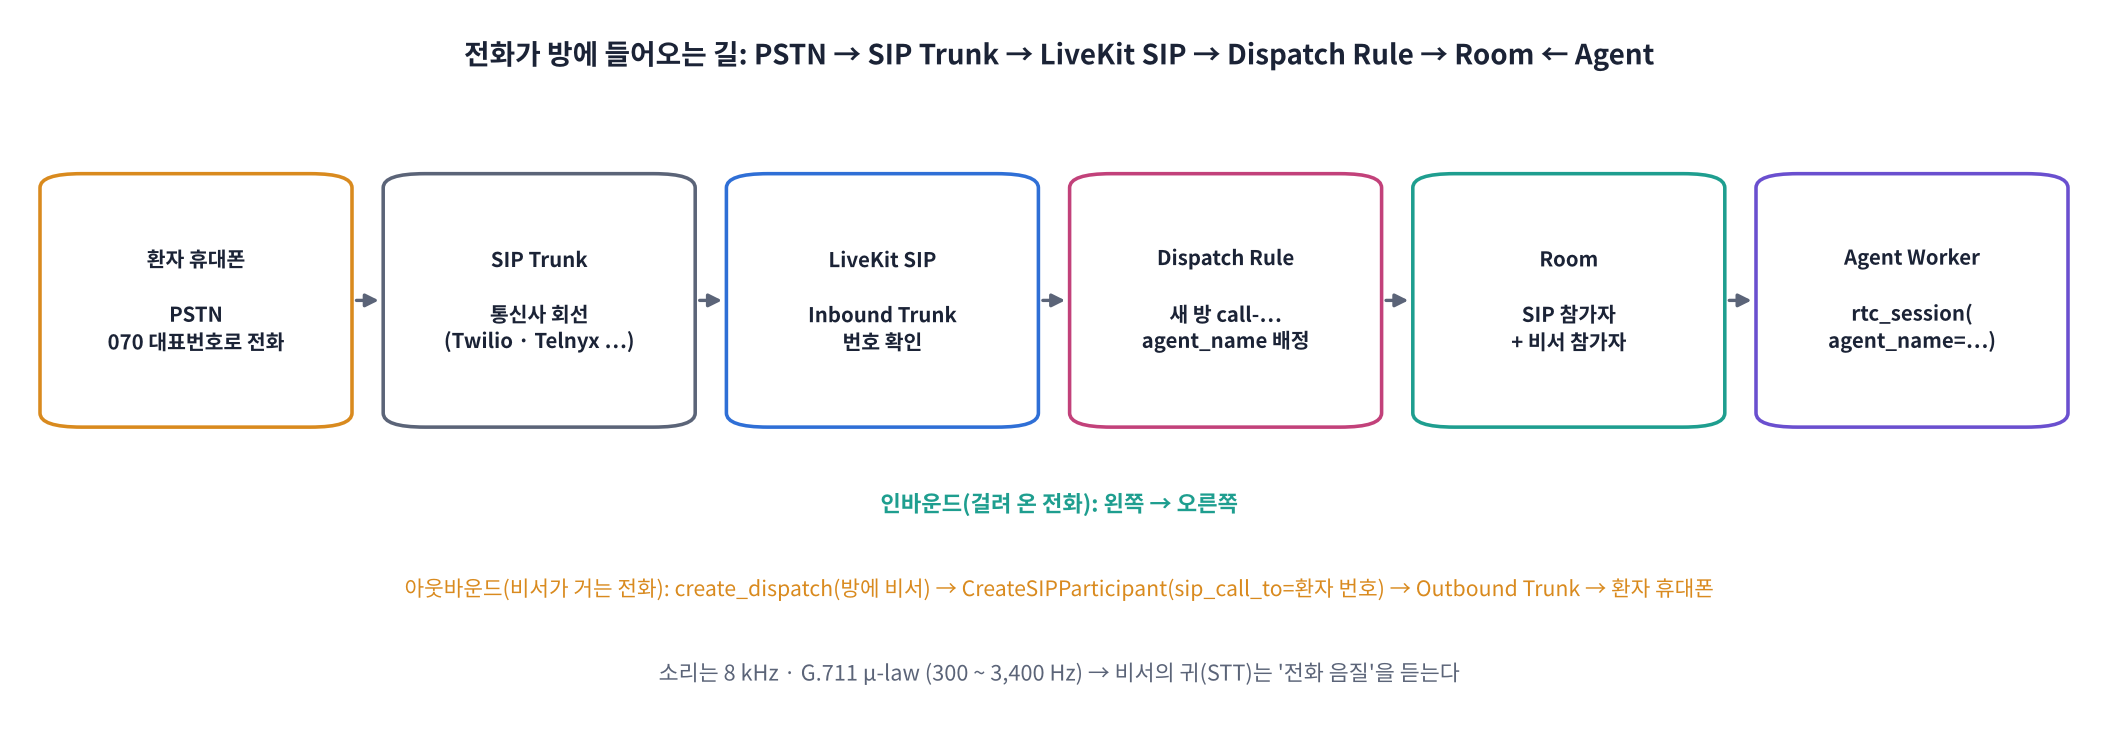

전화망(PSTN)은 WebRTC를 모릅니다. 그래서 **SIP**(Session Initiation Protocol, 인터넷 전화 표준)를 다리로 씁니다.

| 이름 | 하는 일 | 한빛치과 예 |
|---|---|---|
| **PSTN** | 일반 전화망 (휴대폰 · 유선) | 환자가 070 대표번호로 전화 |
| **SIP Trunk** | 전화번호와 인터넷 전화를 이어 주는 통신사 회선 (Twilio · Telnyx · 국내 인터넷전화 사업자) | 070 번호를 LiveKit 주소로 연결 |
| **LiveKit SIP** | SIP 통화 ↔ 방(Room) 참가자로 바꿔 주는 서비스 | 전화 건 사람 = **SIP 참가자** |
| **Inbound Trunk** | "이 번호로 오는 전화를 받겠다" 등록 | 대표번호 등록 |
| **Dispatch Rule** | 걸려 온 전화를 **어느 방**에 넣고 **어느 비서**를 부를지 규칙 | 전화마다 새 방 `call-…` + 비서 `hanbit-phone` |
| **Outbound Trunk + CreateSIPParticipant** | 비서가 **전화를 거는** 길 | 예약 전날 확인 전화 |

> 🍎 **비유**: SIP Trunk는 **국제 전화 교환원**입니다. 전화망 말(PSTN)을 인터넷 말(SIP)로 통역해 우리 방 문 앞까지 데려다주고, Dispatch Rule이라는 **안내 데스크**가 "몇 호실로 가세요, 상담원은 하나 님입니다"라고 배정합니다.
>
> 💬 **쉽게 말하면**: 전화 건 사람도 결국 **방에 들어온 참가자 한 명**입니다(kind = SIP). 비서 쪽 코드는 D29와 거의 같습니다.

> 🎬 **애니메이션 D30-4:** [전화가 방에 들어오는 길](https://imguru-mooc.github.io/AI_Voice/day30/animation.html#sip) — 인바운드(걸려 온 전화) · 아웃바운드(비서가 거는 전화) 단계별

### 2-1. 전화 음질: 8 kHz · μ-law

전화망은 소리를 **8 kHz로 샘플링**하고(들리는 대역 약 300 ~ 3,400 Hz), 한 샘플을 **8비트 μ-law**(G.711)로 압축합니다. 그래서 전화 목소리는 '먹먹하고' 'ㅅ · ㅊ · ㅎ' 같은 높은 소리가 약해집니다. 우리 비서의 귀(STT)도 이 소리를 듣게 됩니다.

📐 **핵심 식 하나 (μ-law 압축)**: `y = sign(x) · ln(1 + μ|x|) / ln(1 + μ)`,  μ = 255
→ 작은 소리는 크게, 큰 소리는 작게 펴서 **8비트로도 작은 목소리를 덜 뭉개지게** 합니다.

> 🎬 **애니메이션 D30-6:** [전화 음질 만들기](https://imguru-mooc.github.io/AI_Voice/day30/animation.html#phone) — 대역 자르기 → 8 kHz → μ-law 8비트, 무엇이 사라지나

In [ ]:
# 🧩 빈칸 실습 5 · 6: 전화 음질 흉내 내기 (대역 300 ~ 3,400 Hz → 8 kHz → μ-law 8비트 → 다시 16 kHz)
from scipy.signal import butter, sosfiltfilt
PHONE_SR = ____                                          # 빈칸 5: 전화망의 샘플링 주파수 (Hz)
MU = ____                                                # 빈칸 6: G.711 μ-law의 μ 값 (북미 · 한국 · 일본)

def mulaw_8bit(x, mu=MU):                                # 압축 → 8비트(256단계)로 자르기 → 다시 펴기
    x = np.clip(x, -1, 1)
    y = np.sign(x) * np.log1p(mu * np.abs(x)) / np.log1p(mu)
    q = np.round((y + 1) / 2 * 255) / 255 * 2 - 1
    return np.sign(q) * ((1 + mu) ** np.abs(q) - 1) / mu

def linear_8bit(x):                                      # 비교용: 압축 없이 그냥 8비트로 자르기
    return np.round((np.clip(x, -1, 1) + 1) / 2 * 255) / 255 * 2 - 1

def phone_line(y, sr=SR):
    sos = butter(6, [300, 3400], btype="bandpass", fs=sr, output="sos")
    y = sosfiltfilt(sos, to_np(y))
    y8 = librosa.resample(y, orig_sr=sr, target_sr=PHONE_SR)
    return librosa.resample(mulaw_8bit(y8), orig_sr=PHONE_SR, target_sr=sr).astype(np.float32)

def snr_db(clean, noisy): return 10 * np.log10(np.sum(clean ** 2) / (np.sum((clean - noisy) ** 2) + 1e-12))

quiet = VOICE1 * 0.1                                     # 작은 목소리 (멀리서 말하는 사람)
print(f"작은 목소리 8비트 SNR: 그냥 자르기 {snr_db(quiet, linear_8bit(quiet)):.1f} dB  vs  μ-law {snr_db(quiet, mulaw_8bit(quiet)):.1f} dB")
PHONE1 = phone_line(VOICE1)
S = np.abs(librosa.stft(PHONE1, n_fft=512)); f = librosa.fft_frequencies(sr=SR, n_fft=512)
high = S[f > 4000].sum() / S.sum()
print(f"전화 음질에서 4 kHz 위 에너지 비율: {high:.4f}")
play(VOICE1, SR, "원래 목소리 (16 kHz)"); play(PHONE1, SR, "전화 음질 (8 kHz · μ-law)")
check(PHONE_SR == 8000 and MU == 255 and high < 0.01, "전화망 샘플링 주파수(Hz)와 G.711 μ-law의 μ 값을 확인하세요.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
PHONE_SR = 8000
MU = 255
```

**해설**: 전화망(G.711)은 **8,000 Hz**로 샘플링하므로 나이퀴스트 한계가 4 kHz이고, 실제로는 300 ~ 3,400 Hz만 지납니다. **μ = 255**(북미 · 한국 · 일본, 유럽은 A-law)는 작은 소리를 크게 펴는 정도입니다. 같은 8비트라도 μ-law가 작은 목소리의 SNR을 크게 높입니다(위 출력 비교).

</details>

In [ ]:
# 🔍 전화 음질이 받아쓰기에 미치는 영향: 스펙트로그램 + 글자 오류율(CER)
def cer(ref, hyp):                                       # 글자 오류율: 공백 · 문장부호 빼고 편집 거리 / 글자 수
    r = re.sub(r"[\s.,?!]", "", ref); h = re.sub(r"[\s.,?!]", "", hyp)
    d = list(range(len(h) + 1))
    for i in range(1, len(r) + 1):
        prev, d[0] = d[0], i
        for j in range(1, len(h) + 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, prev + (r[i - 1] != h[j - 1]))
    return d[len(h)] / max(1, len(r))

import librosa.display
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for ax, (name, y) in zip(axes, [("original 16 kHz", VOICE1), ("phone 8 kHz mu-law", PHONE1)]):
    D = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=512, hop_length=160)), ref=np.max)
    librosa.display.specshow(D, sr=SR, hop_length=160, x_axis="time", y_axis="hz", ax=ax, vmin=-70)
    ax.set_title(name, fontsize=10); ax.axhline(3400, color="w", ls="--", lw=0.8)
plt.tight_layout(); plt.show()

rows = []
for i, (say, v) in enumerate([(SAY1, VOICE1), (SAY2, VOICE2), (SAY3, VOICE3)], 1):
    a, b = stt(v), stt(phone_line(v))
    rows.append({"말": i, "원래 받아쓰기": a, "전화 받아쓰기": b, "CER 원래": round(cer(say, a), 3), "CER 전화": round(cer(say, b), 3)})
display(pd.DataFrame(rows))

### 2-2. SIP 요청서 만들기: Trunk · Dispatch Rule · 전화 걸기

LiveKit 서버에 보내는 SIP 설정은 모두 **요청서(protobuf 메시지)** 입니다. 지금은 **만들어서 내용만 확인**하고, 실제로 보내는 것은 Part 4의 강사 시연 셀(Cloud 키 + Trunk 필요)에서 합니다.

👣 **한 단계씩 (걸려 온 전화)**: ① Inbound Trunk: 대표번호 등록 → ② Dispatch Rule: 전화마다 새 방 `call-…`, 비서 `hanbit-phone`을 명시적으로 부르기 → ③ 작업자는 `@server.rtc_session(agent_name="hanbit-phone")`으로 이 이름의 일감만 받음
👣 **한 단계씩 (비서가 거는 전화)**: ① Outbound Trunk: 통신사 주소 · 발신 번호 → ② 방에 비서를 먼저 배정(`create_dispatch`) → ③ `CreateSIPParticipant`: 그 방으로 **환자 번호에 전화를 걸어** SIP 참가자로 들임

> ⚠️ 전화번호는 개인정보입니다. 아래 번호는 모두 가상의 번호이며, 실습 기록 · 노션에는 실제 번호를 남기지 않습니다(`hide_phone_number`).

In [ ]:
# 🧩 빈칸 실습 7: SIP 요청서 (보내지 않고 내용만 확인)
from google.protobuf.json_format import MessageToDict
AGENT_NAME = "hanbit-phone"                              # 전화 전용 비서 이름 (명시적 배정)
CLINIC_NUMBER = "+827000000000"                          # 가상의 한빛치과 대표번호
PATIENT_NUMBER = "+821000000000"                         # 가상의 환자 번호

inbound = api.CreateSIPInboundTrunkRequest(trunk=api.SIPInboundTrunkInfo(
    name="hanbit-inbound", numbers=[CLINIC_NUMBER], krisp_enabled=True))          # 대표번호로 오는 전화 받기 (+ 잡음 제거)
dispatch = api.CreateSIPDispatchRuleRequest(
    name="hanbit-dispatch",
    rule=api.SIPDispatchRule(dispatch_rule_individual=api.SIPDispatchRuleIndividual(room_prefix="call-")),   # 전화마다 새 방
    room_config=api.RoomConfiguration(agents=[api.RoomAgentDispatch(agent_name=AGENT_NAME)]))              # 그 방에 부를 비서
outbound = api.CreateSIPParticipantRequest(
    sip_trunk_id="ST_xxxxxxxx",                          # Outbound Trunk ID (Part 4 시연에서는 보안 비밀 값)
    ____=PATIENT_NUMBER,                                 # 빈칸 7: 전화를 '걸' 상대 번호
    room_name="call-out-0001", participant_identity="patient-minjun", participant_name="김민준 님",
    wait_until_answered=True, hide_phone_number=True)

for name, req in [("Inbound Trunk", inbound), ("Dispatch Rule", dispatch), ("Outbound Call", outbound)]:
    print(f"── {name}: {type(req).__name__}")
    print(json.dumps(MessageToDict(req), ensure_ascii=False, indent=1)[:420])
check(outbound.sip_call_to == PATIENT_NUMBER and dispatch.room_config.agents[0].agent_name == AGENT_NAME,
      "CreateSIPParticipantRequest에서 '걸 상대 번호' 필드 이름을 확인하세요.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
outbound = api.CreateSIPParticipantRequest(sip_trunk_id=..., sip_call_to=PATIENT_NUMBER, room_name=..., ...)
```

**해설**: `sip_call_to`는 **전화를 걸 번호**(E.164 형식, `+82…`)입니다. `sip_trunk_id`로 어느 통신사 회선을 쓸지, `room_name`으로 상대가 받으면 **어느 방**에 들어올지 정합니다. `wait_until_answered=True`면 상대가 받을 때까지 요청이 기다리고, 받지 않으면 오류가 납니다(부재중 처리).

</details>

### 2-3. 전화 통화일 때 entrypoint에서 달라지는 것

```python
@server.rtc_session(agent_name="hanbit-phone")            # 명시적 배정: 이 이름으로 부를 때만 옴
async def phone_entrypoint(ctx: JobContext):
    await ctx.connect()
    caller = await ctx.wait_for_participant()            # 전화 건 사람 (SIP 참가자)
    if caller.kind == rtc.ParticipantKind.PARTICIPANT_KIND_SIP:
        phone = caller.attributes.get("sip.phoneNumber")  # 발신 번호 · sip.callStatus · sip.trunkID …
    ...
    await session.start(agent=Hana(), room=ctx.room)
```
- **SIP 참가자의 속성**: `sip.phoneNumber`(발신 번호) · `sip.callStatus`(dialing → ringing → active → hangup) · `sip.trunkPhoneNumber`(받은 번호)
- **DTMF**(숫자 버튼): `ctx.room.on("sip_dtmf_received")`로 "1번은 예약, 2번은 수납" 같은 메뉴도 가능
- **전화 끊기**: 방에서 SIP 참가자를 내보내면(`remove_participant`) 전화가 끊깁니다.

**❓ 생각해 보기**: 병원 대표번호에 AI 비서를 연결할 때 기술 외에 **꼭 챙겨야 할 것** 두 가지는?

<details>
<summary>답 보기</summary>

① **녹취 · AI 상담 고지**: 통화 시작에 "AI 상담원이 응대하며 통화 내용이 기록될 수 있습니다"를 알리고, 원하면 사람 상담원으로 돌려야 합니다(D34 개인정보 · 녹취 고지). ② **사람에게 넘기는 길(escalation)**: 응급 · 불만 · 비서가 모르는 질문은 상담원 전화로 돌리는 도구(SIP 전화 돌려주기 `transfer_sip_participant`)를 둡니다. 병원은 개인 건강 정보도 오가므로 저장 · 보관 기간 규칙도 정합니다.

</details>

> 📝 **워크시트 2교시** 10문항을 풀어 보세요.

## Part 3. Speech-to-Speech: 귀 · 머리 · 입을 한 모델로  ·  3교시

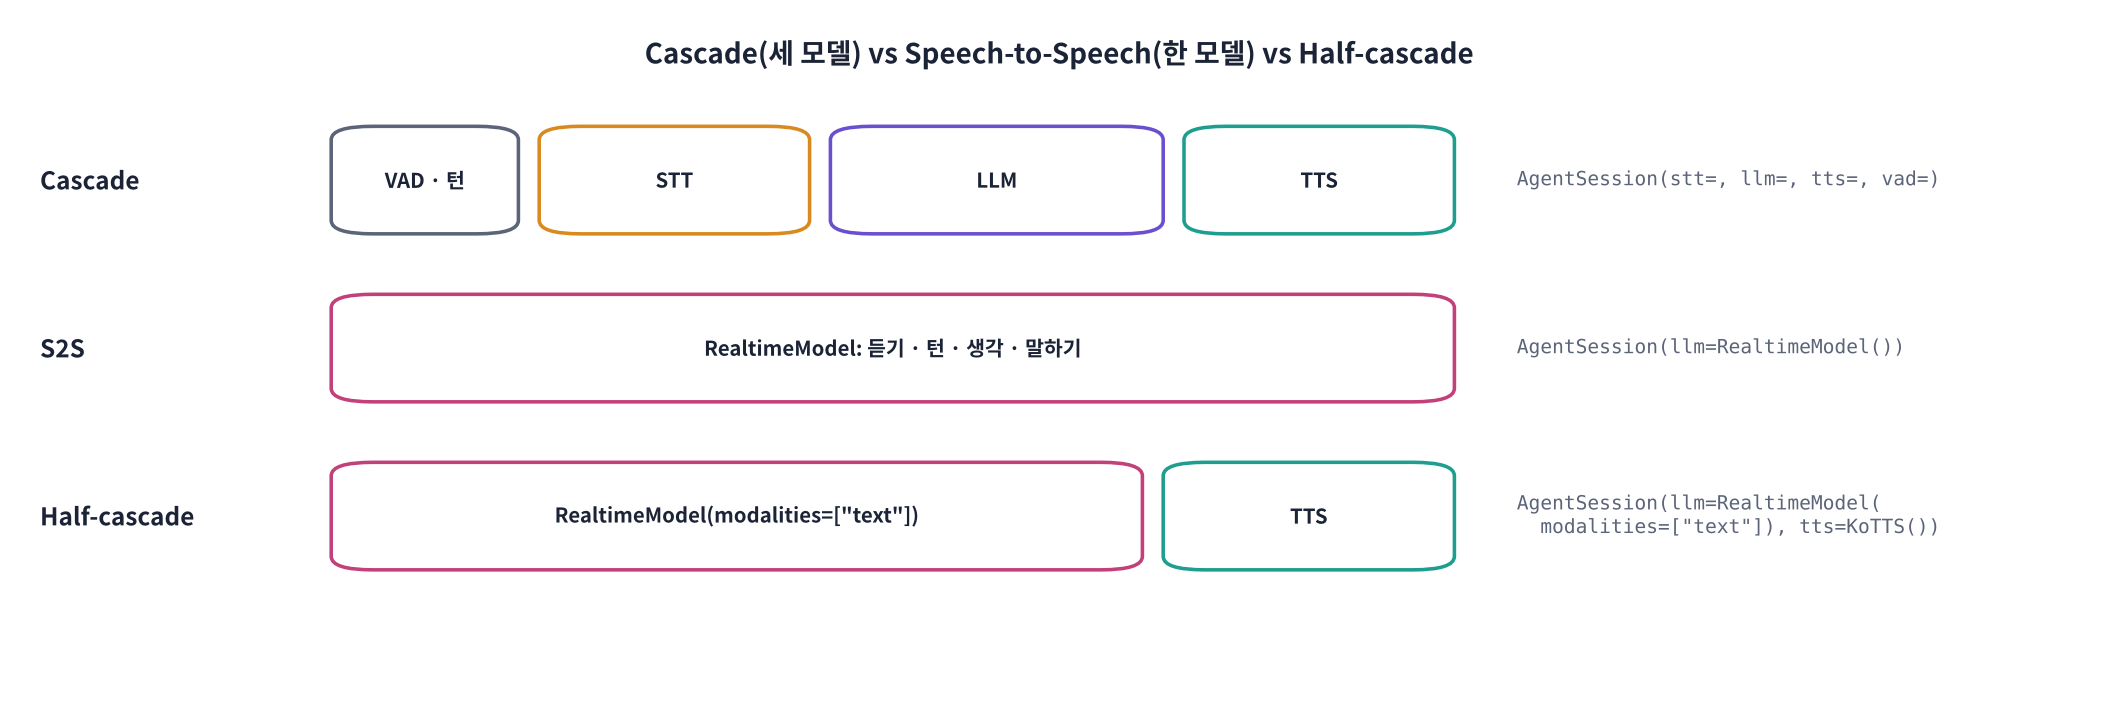

| | **Cascade** (STT → LLM → TTS, D21 ~ D30) | **Speech-to-Speech** (OpenAI Realtime · Gemini Live) |
|---|---|---|
| 모델 | 세 개 (각각 고를 수 있음) | 하나 (소리를 듣고 바로 소리로 답함) |
| 지연 | 단계마다 쌓임 (턴 끝 + STT + TTFT + TTFB) | 짧음 (중간에 글자로 바꾸지 않음) |
| 말투 · 감정 | TTS가 정한 대로 | 사용자 말투 · 감정을 듣고 반영 (웃음 · 머뭇거림) |
| 제어 | 글자가 중간에 있어 **검사 · 고치기 쉬움** (숫자 읽기 · 금칙어) | 중간 글자가 없어 **발음 · 숫자 읽기 제어가 어려움** |
| 목소리 | 아무 TTS (복제 목소리 포함) | 모델이 주는 목소리 몇 가지 |
| 로컬 · 온프레미스 | 가능 (오늘 노트북) | 사실상 클라우드 전용 |
| 비용 | 단계별로 싼 것 조합 | 오디오 토큰 단가가 높은 편 |

> 💬 **쉽게 말하면**: Cascade는 **통역사 세 명이 이어 말하기**, S2S는 **처음부터 그 말을 하는 사람 한 명**입니다. 빠르고 자연스럽지만, 중간에 대본(글자)이 없어 고치기 어렵습니다.
>
> 🧪 **Half-cascade**: S2S 모델이 **듣기 · 생각은 하고 글자로만** 답하게 한 뒤(`modalities=["text"]`), 입은 우리 TTS가 맡는 중간형. 빠른 귀 · 머리 + 우리가 고른 목소리 · 숫자 읽기 제어.

> 🎬 **애니메이션 D30-7:** [Cascade vs S2S 지연](https://imguru-mooc.github.io/AI_Voice/day30/animation.html#s2s) — 단계별 막대를 바꿔 보며 어디서 시간이 줄어드는지

### 3-1. 같은 대본, 다른 머리: RealtimeModel 꽂기

LiveKit에서 S2S 모델은 **`llm=` 자리에 꽂는 `RealtimeModel`** 입니다. 대본(`Hana` · `Billing`)과 도구는 그대로 쓰고, `stt=` · `tts=`는 비웁니다(Half-cascade면 `tts=`만 채움). 만들기만 할 때는 **연결하지 않으므로** 키가 없어도 능력(capabilities)을 볼 수 있습니다.

> 🎬 **애니메이션 D30-8:** [능력(capabilities) 표 읽기](https://imguru-mooc.github.io/AI_Voice/day30/animation.html#caps) — 모델마다 다른 능력이 세션 동작을 어떻게 바꾸나

In [ ]:
# 🧩 빈칸 실습 8 · 9: S2S 모델 만들기 (연결은 아직 안 함) · 능력(capabilities) 비교
OPENAI_KEY, GEMINI_KEY = secret("OPENAI_API_KEY"), secret("GEMINI_API_KEY")

rt_openai = lk_openai.realtime.____(voice="marin", api_key=OPENAI_KEY or "not-set")       # 빈칸 8: S2S 모델 클래스 이름
rt_gemini = lk_google.realtime.RealtimeModel(voice="Kore", api_key=GEMINI_KEY or "not-set")   # ✏️ 목소리: Puck · Kore · Charon …
rt_half = lk_openai.realtime.RealtimeModel(____=["text"], api_key=OPENAI_KEY or "not-set")   # 빈칸 9: 글자로만 답하게 (Half-cascade)

CAPS = ["audio_output", "turn_detection", "user_transcription", "auto_tool_reply_generation", "message_truncation", "supports_say"]
rows = []
for name, m in [("OpenAI Realtime", rt_openai), ("Gemini Live", rt_gemini), ("OpenAI Half-cascade", rt_half)]:
    rows.append({"모델": name, "model": m.model, **{c: getattr(m.capabilities, c) for c in CAPS}})
display(pd.DataFrame(rows))
print("키:", "OpenAI 있음" if OPENAI_KEY else "OpenAI 없음", "·", "Gemini 있음" if GEMINI_KEY else "Gemini 없음", "(값은 출력하지 않음)")
check(isinstance(rt_openai, lk_llm.RealtimeModel) and rt_openai.capabilities.audio_output and not rt_half.capabilities.audio_output,
      "openai.realtime 안의 모델 클래스 이름과, 답의 형태(글자 · 소리)를 정하는 인자 이름을 확인하세요.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
rt_openai = lk_openai.realtime.RealtimeModel(voice="marin", api_key=...)
rt_half = lk_openai.realtime.RealtimeModel(modalities=["text"], api_key=...)
```

**해설**: `RealtimeModel`은 `lk_llm.RealtimeModel`을 물려받은 S2S 플러그인입니다. `AgentSession(llm=RealtimeModel(...))`처럼 **LLM 자리**에 꽂으면 세션이 STT · TTS 없이 소리를 바로 주고받습니다. `modalities=["text"]`면 `audio_output=False`가 되어 세션이 우리 `tts=`로 말합니다(Half-cascade). 표의 `supports_say=False`는 **정해진 문장 읽기(`session.say`)가 안 된다**는 뜻이라, S2S의 인사는 `generate_reply(instructions=...)`로 시킵니다.

</details>

### 3-2. (키가 있으면) S2S로 같은 통화 해 보기

키가 있으면 아래 셀이 **같은 가짜 마이크(사용자 말 세 마디) · 같은 대본(Hana · Billing) · 같은 도구**로 S2S 통화를 합니다. OpenAI 키가 있으면 OpenAI Realtime, 아니면 Gemini Live를 씁니다.

> ⚠️ S2S는 **스스로 턴을 판단**하므로(`turn_detection=True`) 우리 VAD를 넣지 않습니다. 한국어 숫자 · 고유명사 발음은 모델마다 다르니 꼭 들어 보세요.

In [ ]:
# ▶️ S2S 통화 (OpenAI Realtime 또는 Gemini Live, 키가 있을 때만 · 실제 시간 약 40 ~ 60초)
async def s2s_call(rt, voices):
    session = AgentSession(llm=rt, userdata=CallInfo()); t0 = time.perf_counter()   # stt · tts · vad 없이 머리 하나
    log = CallLog(session, t0)
    mic, spk = attach_fake_io(session, voices, t0)
    await session.start(agent=Hana())
    session.generate_reply(instructions="한빛치과 예약 도우미 하나라고 한 문장으로 인사하세요.")   # say() 대신
    await wait_call(mic)
    info = session.userdata
    await session.aclose()
    return dict(log=log, mic=mic, spk=spk, info=info)

S2S_MODEL = rt_openai if OPENAI_KEY else (rt_gemini if GEMINI_KEY else None)
res_s2s = None
if S2S_MODEL is not None:
    res_s2s = await s2s_call(S2S_MODEL, [VOICE1, VOICE2, VOICE3])
    plot_call(res_s2s, f"speech-to-speech: {S2S_MODEL.model}")
    display(turn_table(res_s2s))
    play(mix(res_s2s, [VOICE1, VOICE2, VOICE3]), SR, "S2S 통화 전체")
    print("공유 메모:", res_s2s["info"])
else:
    print("S2S 건너뜀: OPENAI_API_KEY 또는 GEMINI_API_KEY가 없습니다. (3-1의 능력 표와 애니메이션 D30-7로 비교)")

**❓ 생각해 보기**: S2S가 더 빠르고 자연스럽다면 한빛치과 전화 비서는 무조건 S2S가 좋을까요? **Cascade를 고를 이유**를 두 가지 들어 보세요.

<details>
<summary>답 보기</summary>

① **정확한 숫자 · 고유명사 읽기**: 예약 번호 'HB-0001', 가격 '1만 5천 원', 날짜를 틀리면 안 됩니다. Cascade는 TTS 바로 앞에서 글자를 검사 · 정규화(D16 `normalize_ko`)할 수 있습니다. ② **비용 · 데이터 위치**: 통화량이 많으면 오디오 토큰 단가가 부담이고, 병원 정보가 외부로 나가지 않아야 하면 로컬 STT · LLM · TTS(Cascade)만 가능합니다. 그 밖에 원하는 목소리(브랜드 목소리), 단계별 장애 대응(한 부품만 교체)도 Cascade의 장점입니다. 그래서 실무에서는 **Half-cascade**나 '상황별 혼합'을 많이 씁니다.

</details>

> 📝 **워크시트 3교시** 10문항을 풀어 보세요.

## Part 4. 통합: 전화 상담 리허설 (전화 음질 + Handoff + 작업자)  ·  4교시

오늘 만든 것을 한 통화에 모읍니다.

| 부품 | 어디서 |
|---|---|
| 전화 음질의 사용자 말 세 마디 | Part 2 `phone_line` |
| 예약 담당 → 수납 담당 Handoff, 도구, userdata | Part 1 `Hana` · `Billing` · `CallInfo` |
| 전화 전용 작업자 (`agent_name="hanbit-phone"`) | Part 2-3 · D29 Part 4 |
| 통화 기록 저장 (`add_shutdown_callback`) | 이번 절 |

> 💬 **쉽게 말하면**: 진짜 전화 대신 **전화 음질로 녹음한 환자 말**을 가짜 마이크로 흘려, 전화 비서가 처음부터 끝까지 상담하는 **리허설**입니다. 진짜 전화(SIP)로 바꿀 때 바뀌는 것은 마이크 쪽뿐입니다.

> 🎬 **애니메이션 D30-5:** [전화 한 통의 일생](https://imguru-mooc.github.io/AI_Voice/day30/animation.html#dispatch) — Dispatch → entrypoint → 예약 → Handoff → 수납 → 끊김 → 기록 저장

In [ ]:
# ☎️ 전화 전용 작업자 + 가짜 일감(fake job)으로 전화 상담 리허설 (실제 시간 약 40 ~ 70초)
from dataclasses import asdict
PHONE_VOICES = [phone_line(v) for v in (VOICE1, VOICE2, VOICE3)]
CALLS = {}

def save_call_log(session, rec, path):                   # 통화 기록: 대화 · 도구 · 담당 교체 · 공유 메모 · 사용량
    log = {"room": rec["room"], "phone": rec["info"].phone, "userdata": asdict(rec["info"]),
           "history": session.history.to_dict(exclude_timestamp=False),
           "usage": str(session.usage)}
    with open(path, "w", encoding="utf-8") as f:
        json.dump(log, f, ensure_ascii=False, indent=1, default=str)
    return path

phone_server = AgentServer(job_executor_type=JobExecutorType.THREAD)

@phone_server.rtc_session(agent_name=AGENT_NAME)         # 명시적 배정: Dispatch Rule이 'hanbit-phone'을 부를 때만
async def phone_entrypoint(ctx: JobContext):
    await ctx.connect()
    info = CallInfo()
    session = AgentSession(stt=WhisperSTT(), llm=make_llm(), tts=KoTTS(), vad=VAD, userdata=info,
                           turn_handling={"endpointing": {"min_delay": 0.8}})   # ✏️ 전화: 말 사이 쉼이 길어 턴 끝 판단을 0.5 → 0.8초
    t0 = time.perf_counter()
    rec = dict(log=CallLog(session, t0), room=ctx.room.name, fake=ctx.is_fake_job(), info=info)
    if ctx.is_fake_job():                                # 리허설: 전화 음질 녹음을 가짜 마이크로
        rec["mic"], rec["spk"] = attach_fake_io(session, PHONE_VOICES, t0)
        info.phone = "+82100000**** (리허설)"
    else:                                                # 진짜 전화: SIP 참가자의 발신 번호 읽기
        caller = await ctx.wait_for_participant()
        if caller.kind == rtc.ParticipantKind.PARTICIPANT_KIND_SIP:
            info.phone = caller.attributes.get("sip.phoneNumber")
    CALLS[ctx.job.id] = rec

    async def on_end():                                  # 통화가 끝나면 (작업 종료 시) 기록 저장
        rec["log_path"] = save_call_log(session, rec, f"call_{ctx.room.name}.json")
    ctx.add_shutdown_callback(on_end)

    await session.start(agent=Hana(), room=ctx.room)
    session.say("한빛치과입니다. 이 통화는 AI 상담원이 응대하며 상담 내용이 기록됩니다. 무엇을 도와드릴까요?")   # 녹취 · AI 고지
    if ctx.is_fake_job():
        await wait_call(rec["mic"])
        rec["log_path"] = save_call_log(session, rec, f"call_{ctx.room.name}.json")
        await session.aclose(); rec["done"] = True

phone_task = asyncio.ensure_future(phone_server.run(devmode=True, unregistered=True))
await asyncio.sleep(1.0)
await phone_server.simulate_job("call-rehearsal", fake_job=True)
t_end = time.perf_counter() + 200
while time.perf_counter() < t_end and not any(r.get("done") for r in CALLS.values()):
    await asyncio.sleep(0.2)
res_phone = next(r for r in CALLS.values() if r.get("fake"))
plot_call(res_phone, "phone rehearsal: Hana (booking) -> Billing (price), 8 kHz mu-law user voice")
display(turn_table(res_phone))
play(mix(res_phone, PHONE_VOICES), SR, "전화 상담 리허설 전체")
print("공유 메모:", res_phone["info"])
print("통화 기록 파일:", res_phone.get("log_path"))
await phone_server.aclose()

In [ ]:
# 📄 통화 기록 열어 보기: 누가 · 무엇을 · 어떤 도구로 · 담당은 언제 바뀌었나
call = json.load(open(res_phone["log_path"], encoding="utf-8"))
rows = []
for it in call["history"]["items"]:
    t = it.get("type")
    if t == "message":
        rows.append({"종류": it["role"], "내용": " ".join(c for c in it.get("content", []) if isinstance(c, str))[:50]})
    elif t == "function_call":
        rows.append({"종류": "도구 주문", "내용": f'{it["name"]}({pretty(it.get("arguments", ""))[:60]})'})
    elif t == "function_call_output":
        rows.append({"종류": "도구 결과", "내용": str(it.get("output", ""))[:50]})
    elif t == "agent_handoff":
        rows.append({"종류": "담당 교체", "내용": f'{it.get("old_agent_id")} → {it.get("new_agent_id")}'})
display(pd.DataFrame(rows))
print("예약:", call["userdata"]["bookings"], "· 담당 교체:", call["userdata"]["handoffs"])

### 4-2. (강사 시연) 진짜 전화 걸기: LiveKit Cloud + Outbound Trunk

필요한 것: Colab 보안 비밀에 `LIVEKIT_URL` · `LIVEKIT_API_KEY` · `LIVEKIT_API_SECRET` · `SIP_OUTBOUND_TRUNK_ID` · `DEMO_PHONE`(내 휴대폰, E.164 `+8210…`). Trunk는 [LiveKit Cloud → Telephony](https://cloud.livekit.io)에서 통신사(Twilio · Telnyx 등) 정보로 만듭니다.

👣 이 셀이 하는 일: ① 같은 `phone_entrypoint`를 Cloud에 **등록**한 작업자로 켬 → ② 새 방에 `hanbit-phone` 비서를 **배정**(`create_dispatch`) → ③ 그 방으로 **내 휴대폰에 전화**(`create_sip_participant`) → 받으면 비서가 고지 · 인사 → 통화 → 끊으면 `call_….json` 저장

In [ ]:
# ☎️ (선택 · 강사 시연) 내 휴대폰으로 비서가 전화 걸기
RUN_SIP = False                                          # ✏️ True로 바꾸고 실행
SIP_KEYS = {k: secret(k) for k in ["LIVEKIT_URL", "LIVEKIT_API_KEY", "LIVEKIT_API_SECRET", "SIP_OUTBOUND_TRUNK_ID", "DEMO_PHONE"]}
print("SIP 시연 준비:", {k: ("있음" if v else "없음") for k, v in SIP_KEYS.items()}, "· RUN_SIP =", RUN_SIP)   # 값은 출력하지 않음
if RUN_SIP and all(SIP_KEYS.values()):
    cloud_phone = AgentServer(job_executor_type=JobExecutorType.THREAD, ws_url=SIP_KEYS["LIVEKIT_URL"],
                              api_key=SIP_KEYS["LIVEKIT_API_KEY"], api_secret=SIP_KEYS["LIVEKIT_API_SECRET"])
    cloud_phone.rtc_session(agent_name=AGENT_NAME)(phone_entrypoint)
    cloud_task = asyncio.ensure_future(cloud_phone.run(devmode=True))
    await asyncio.sleep(3.0)
    room_name = f"call-out-{int(time.time()) % 100000:05d}"
    lkapi = api.LiveKitAPI(SIP_KEYS["LIVEKIT_URL"], SIP_KEYS["LIVEKIT_API_KEY"], SIP_KEYS["LIVEKIT_API_SECRET"])
    await lkapi.agent_dispatch.create_dispatch(api.CreateAgentDispatchRequest(agent_name=AGENT_NAME, room=room_name))
    try:
        await lkapi.sip.create_sip_participant(api.CreateSIPParticipantRequest(
            sip_trunk_id=SIP_KEYS["SIP_OUTBOUND_TRUNK_ID"], sip_call_to=SIP_KEYS["DEMO_PHONE"], room_name=room_name,
            participant_identity="demo-callee", participant_name="시연 수신자", wait_until_answered=True, hide_phone_number=True))
        print("📞 전화 연결됨:", room_name, "→ 통화를 마치고 끊은 뒤 아래 정리 셀을 실행하세요.")
    except Exception as e:
        print("⚠️ 전화 실패:", type(e).__name__, str(e)[:120])
    await lkapi.aclose()
elif RUN_SIP:
    print("⚠️ 보안 비밀 5개를 모두 넣어 주세요.")

In [ ]:
# 📊 Cascade vs S2S: 오늘 잰 숫자로 비교표 만들기
def e2e_stats(res):
    if not res: return None
    v = [it.metrics.get("e2e_latency") for it in res["log"].items if it.role == "assistant" and it.metrics and it.metrics.get("e2e_latency")]
    return (round(float(np.median(v)), 2), len(v)) if v else None

cmp = pd.DataFrame([
    {"방식": f"Cascade ({PROVIDER} LLM)", "말 끝 → 첫 소리 중앙값(초) · 턴 수": e2e_stats(res_phone), "도구 · Handoff": "✔ (오늘 리허설)",
     "숫자 읽기 제어": "✔ normalize_ko", "목소리 선택": "✔ 아무 TTS", "로컬 가능": "✔" if PROVIDER == "local" else "△ (LLM만 클라우드)"},
    {"방식": f"S2S ({S2S_MODEL.model if S2S_MODEL else '키 없음'})", "말 끝 → 첫 소리 중앙값(초) · 턴 수": e2e_stats(res_s2s) if res_s2s else "키 없음 · 측정 안 함",
     "도구 · Handoff": "✔ (같은 Agent)" if res_s2s else "✔ (지원)", "숫자 읽기 제어": "✘ 모델에 맡김", "목소리 선택": "△ 제공 목소리만", "로컬 가능": "✘"},
])
display(cmp)
print("⚠️ 이 노트북의 Cascade 숫자는 T4 · Colab 기준이며, 전화망 · WebRTC 지연(수십 ~ 수백 ms)은 포함되지 않았습니다.")

**❓ 생각해 보기**: 리허설 기록(`call_….json`)에는 이름 · 전화번호 · 진료 정보가 들어 있습니다. 실서비스에서 이 파일을 어떻게 다뤄야 할까요?

<details>
<summary>답 보기</summary>

① **최소 수집**: 필요한 항목만 저장하고 전화번호는 가리거나(`hide_phone_number`, 끝자리 마스킹) 해시로 바꿉니다. ② **보관 기간 · 접근 권한**: 정해진 기간이 지나면 지우고, 볼 수 있는 사람을 제한합니다. ③ **고지 · 동의**: 통화 시작의 녹취 · AI 고지(오늘 `session.say`)를 기록과 함께 남깁니다. ④ 실습에서도 실제 번호 · 녹음을 노션 · 깃허브에 올리지 않습니다. 자세한 내용은 D34(운영 & 보안)에서 다룹니다.

</details>

> 📝 **워크시트 4교시** 10문항을 풀어 보세요.

## Part 5. 정리

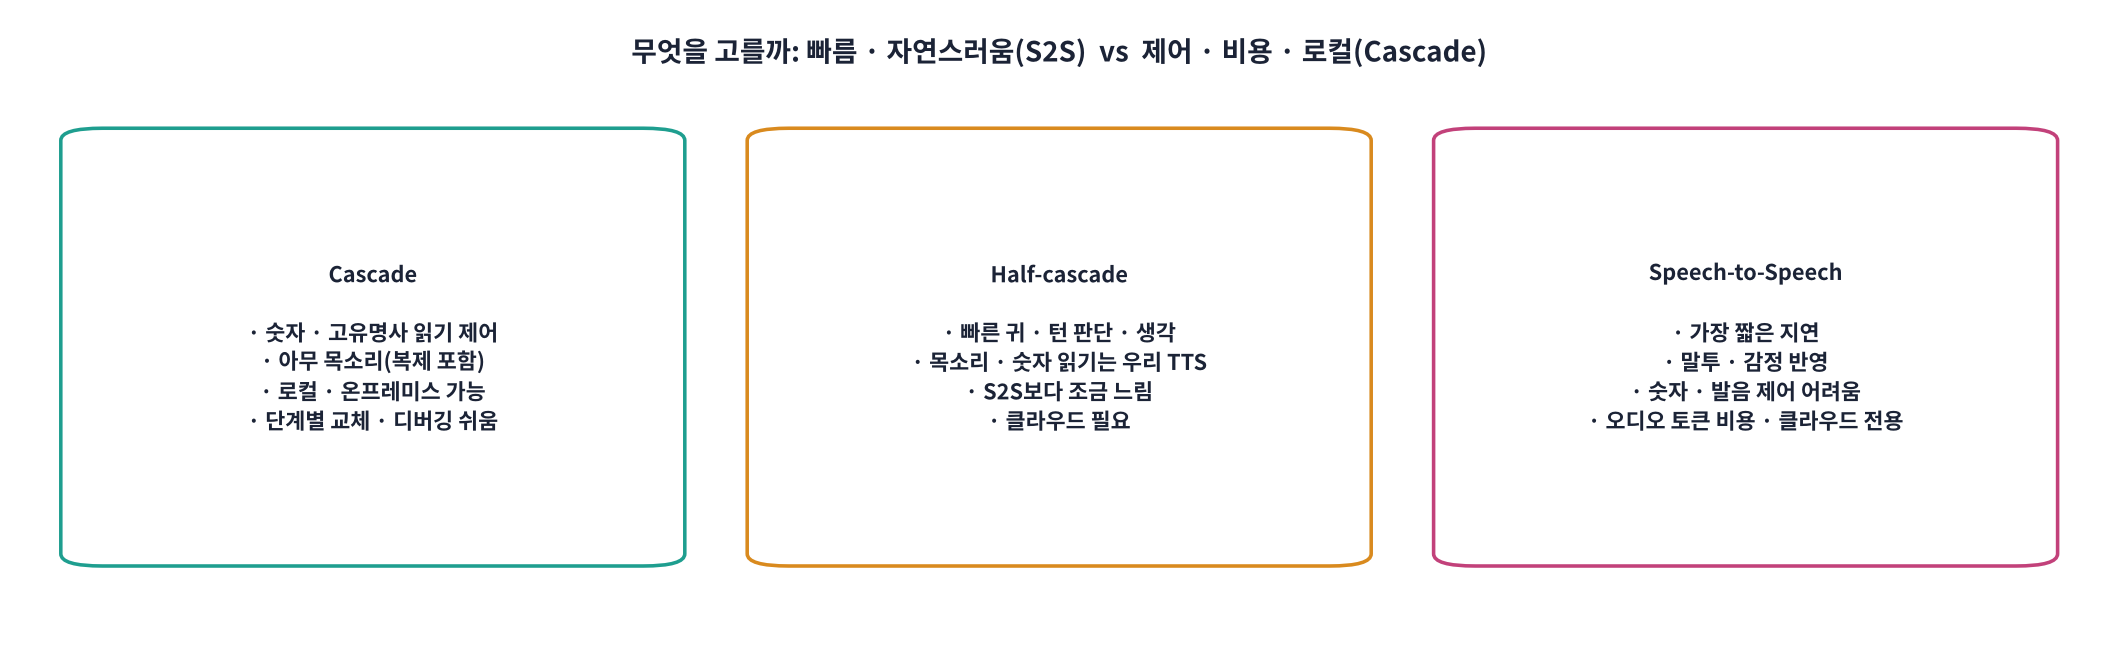

| 오늘 만든 것 | LiveKit 이름 | 한 줄 요약 |
|---|---|---|
| 로컬 LLM 도구 호출 | `lk_llm.FunctionToolCall` | Qwen3의 `<tool_call>` 글자 → LiveKit 도구 주문서 |
| 도구 | `@function_tool` | 이름 · docstring · 타입 힌트 = LLM이 보는 설명서 |
| 공유 메모 | `RunContext.userdata` · `AgentSession(userdata=…)` | 담당이 바뀌어도 이어지는 통화 정보 |
| 담당 교체 | 도구가 `Agent`를 돌려줌 · `contains_agent_handoff` | 예약 → 수납, 대화(`chat_ctx`)를 넘겨 이어 응대 |
| 전화 음질 | 8 kHz · μ-law(μ = 255) | 300 ~ 3,400 Hz만 남음 → 받아쓰기 오류 증가 |
| SIP | Inbound Trunk · Dispatch Rule · `CreateSIPParticipant(sip_call_to=…)` | 전화 건 사람 = SIP 참가자, 비서는 `agent_name`으로 배정 |
| S2S | `RealtimeModel` · `modalities=["text"]` | 귀 · 머리 · 입을 한 모델로, 또는 Half-cascade |
| 통화 기록 | `session.history` · `add_shutdown_callback` | 끝나면 저장, 개인정보는 최소 · 마스킹 |

### ✅ 오늘의 확인
- [ ] 도구 호출 한 바퀴(주문 → 실행 → 결과 → 다시 말하기)를 설명하고, 로컬 LLM에도 붙였다.
- [ ] 예약 → 수납 Handoff가 `userdata`와 함께 일어나는 것을 글자 시험과 음성 리허설로 확인했다.
- [ ] 전화 음질이 받아쓰기에 미치는 영향을 소리 · 그림 · CER로 확인하고, SIP 요청서를 만들었다.
- [ ] S2S 모델의 능력 표를 읽고, Cascade와 S2S 중 무엇을 고를지 근거를 말할 수 있다.

### 🔜 다음 주 (7주차) 예고: 서비스 배포 & 운영
- **D31 FastAPI 음성 API 서버**: STT · TTS REST · WebSocket 엔드포인트, 비동기 처리
- 6주차에 만든 실시간 비서를 **서비스로 띄우고(D33 컨테이너)**, **로그 · 비용 · 개인정보(D34)** 를 챙깁니다.

> 🎬 **애니메이션 D30-9:** [정리 퀴즈](https://imguru-mooc.github.io/AI_Voice/day30/animation.html#recap) — 상황별로 Handoff · 도구 · SIP · S2S 중 무엇을 쓸지 고르기